In [2]:
%pip install matplotlib seaborn pandas


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
BASE_DIR = Path().resolve().parent.parent / "output_files"
aiup_csv_path = BASE_DIR / "ai_usage_profile.csv"
sqp_csv_path = BASE_DIR / "software_quality_profile.csv"
aiup_eop_path = BASE_DIR / "ai_usage_profile_eop.csv"
aicp_csv_path = BASE_DIR / "ai_component_profile.csv"

aiup_df = pd.read_csv(aiup_csv_path)
sqp_df = pd.read_csv(sqp_csv_path)
aiup_eop_df = pd.read_csv(aiup_eop_path)
aicp_df = pd.read_csv(aicp_csv_path)

In [5]:
# Data shape

print("AI Usage Profile shape:", aiup_df.shape)
print("Software Quality Profile shape:", sqp_df.shape)
print("AI Usage Profile EOP shape:", aiup_eop_df.shape)
print("AI Component Profile shape:", aicp_df.shape)

total_rows = aiup_df.shape[0] + sqp_df.shape[0] + aiup_eop_df.shape[0] + aicp_df.shape[0]
print("Total rows across all datasets:", total_rows)

total_individual_datapoints = (
    aiup_df.shape[0] * aiup_df.shape[1] +
    sqp_df.shape[0] * sqp_df.shape[1] +
    aiup_eop_df.shape[0] * aiup_eop_df.shape[1] +
    aicp_df.shape[0] * aicp_df.shape[1]
)
print("Total individual data points across all datasets:", total_individual_datapoints)

AI Usage Profile shape: (13213, 24)
Software Quality Profile shape: (17011, 60)
AI Usage Profile EOP shape: (11404, 9)
AI Component Profile shape: (92, 13)
Total rows across all datasets: 41720
Total individual data points across all datasets: 1441604


In [6]:
num_projoects_aiup = aiup_df['repository_id'].nunique()
num_projoects_sqp = sqp_df['repository_id'].nunique()
num_projoects_aiup_eop = aiup_eop_df['repository_id'].nunique()
num_projoects_aicp = aicp_df['repository_id'].nunique()

print("Unique projects in AI Usage Profile:", num_projoects_aiup)
print("Unique projects in Software Quality Profile:", num_projoects_sqp)
print("Unique projects in AI Usage Profile EOP:", num_projoects_aiup_eop)
print("Unique projects in AI Component Profile:", num_projoects_aicp)

Unique projects in AI Usage Profile: 88
Unique projects in Software Quality Profile: 91
Unique projects in AI Usage Profile EOP: 91
Unique projects in AI Component Profile: 92


In [7]:
# Outline discrepancies in project counts across datasets
projects_aiup = set(aiup_df['repository_id'].unique())
projects_sqp = set(sqp_df['repository_id'].unique())
projects_aiup_eop = set(aiup_eop_df['repository_id'].unique())
projects_aicp = set(aicp_df['repository_id'].unique())

all_projects = projects_aicp  # AICP is ground truth — covers all 92

# Build a presence matrix
rows = []
for repo in sorted(all_projects):
    rows.append({
        "repository_id": repo,
        "in_AICP":      repo in projects_aicp,
        "in_AIUP_EOP":  repo in projects_aiup_eop,
        "in_SQP":       repo in projects_sqp,
        "in_AIUP":      repo in projects_aiup,
    })

presence_df = pd.DataFrame(rows)

# Flag repos that are missing from at least one profile
presence_df["any_missing"] = ~(
    presence_df["in_AICP"] &
    presence_df["in_AIUP_EOP"] &
    presence_df["in_SQP"] &
    presence_df["in_AIUP"]
)

print("=== Repositories missing from at least one profile ===")
display(presence_df[presence_df["any_missing"]].reset_index(drop=True))

print("\n=== Summary counts ===")
summary = pd.DataFrame({
    "Profile": ["AICP", "AIUP_EOP", "SQP", "AIUP"],
    "Repositories": [
        len(projects_aicp),
        len(projects_aiup_eop),
        len(projects_sqp),
        len(projects_aiup),
    ],
    "Missing vs AICP": [
        0,
        len(projects_aicp - projects_aiup_eop),
        len(projects_aicp - projects_sqp),
        len(projects_aicp - projects_aiup),
    ]
})
display(summary)

=== Repositories missing from at least one profile ===


,repository_id,in_AICP,in_AIUP_EOP,in_SQP,in_AIUP,any_missing
0,2018_TDT4290-CiDev_api-gateway,True,False,True,False,True
1,2020_Kundestyrt-Gruppe-10_Purefolio-backend,True,True,False,True,True
2,2021_kaffikaffi_group-1-tdt4290,True,True,True,False,True
3,2022_kundestyrt-gruppe-5-2022_passport-mrz-rea...,True,True,True,False,True
4,2024_hanlun0804_tdt4290,True,True,True,False,True



=== Summary counts ===


,Profile,Repositories,Missing vs AICP
0,AICP,92,0
1,AIUP_EOP,91,1
2,SQP,91,1
3,AIUP,88,4


In [8]:
sqp_df["project_year"] = pd.to_datetime(sqp_df["date"], errors='coerce', utc=True).dt.year
aicp_df["project_year"] = aicp_df["repository_id"].str.slice(0, 4).astype(int)

In [9]:
projects_per_year_aiup = aiup_df.groupby('project_year')['repository_id'].nunique()
projects_per_year_sqp = sqp_df.groupby('project_year')['repository_id'].nunique()
projects_per_year_aiup_eop = aiup_eop_df.groupby('project_year')['repository_id'].nunique()
projects_per_year_aicp = aicp_df.groupby('project_year')['repository_id'].nunique()

print("Projects per year in AI Usage Profile:\n", projects_per_year_aiup)
print("Projects per year in Software Quality Profile:\n", projects_per_year_sqp)
print("Projects per year in AI Usage Profile EOP:\n", projects_per_year_aiup_eop)
print("Projects per year in AI Component Profile:\n", projects_per_year_aicp)

Projects per year in AI Usage Profile:
 project_year
2017     2
2018    13
2019     6
2020    21
2021     8
2022    16
2023     6
2024     5
2025    11
Name: repository_id, dtype: int64
Projects per year in Software Quality Profile:
 project_year
2017     2
2018    14
2019     6
2020    20
2021     9
2022    17
2023     6
2024     6
2025    11
Name: repository_id, dtype: int64
Projects per year in AI Usage Profile EOP:
 project_year
2017     2
2018    13
2019     6
2020    21
2021     9
2022    17
2023     6
2024     6
2025    11
Name: repository_id, dtype: int64
Projects per year in AI Component Profile:
 project_year
2017     2
2018    14
2019     6
2020    21
2021     9
2022    17
2023     6
2024     6
2025    11
Name: repository_id, dtype: int64


In [10]:
# import pandas as pd
# from pandas import col
# from scipy import stats
# import numpy as np
# display(aiup_df.head())

# # Plot the distribution of the mean droiddetect probabilities per year
# for year in sorted(aiup_df['project_year'].unique()):
#     subset = aiup_df[aiup_df['project_year'] == year]
#     plt.figure(figsize=(12, 6))
#     sns.histplot(subset['prob_machine_droiddetect'], bins=40, kde=True)
#     plt.title(r"Distribution of $\tau$ for projects from " + str(year) + r" ($\bar{\tau}$) = " + f"{subset['prob_machine_droiddetect'].mean():.2f}", fontsize=16)
#     plt.xlabel(r"$\bar{\tau}$", fontsize=14)
#     plt.tight_layout()
#     plt.show()
    

,repository_id,snapshot_commit,date,bugs,classes,code_smells,cognitive_complexity,comment_lines,comment_lines_density,complexity,...,info_ratio,security_ratio,reliability_ratio,maintainability_ratio,languages,issues_per_kloc,debt_per_kloc,complexity_per_kloc,quality_index,project_year
0,2017_KDPRO-SINTEF_BowtieTool,69b30a5a551aea56b4cf200f74e6fcf23abe2c1d,2017-11-21 09:33:58+00:00,44845,378.0,115263,33653.0,52507,25.5,28805.0,...,0.000824,0.000006,0.316453,0.720478,"[{'val': 'web', 'count': 142370}, {'val': 'js'...",1041.793007,3914.201684,187.427612,4.75,2017
1,2017_egrimstad_scalpel,7a29c5921df33ccdad8f21ac8336c06964740ad8,2017-11-23 11:29:47+00:00,6,10.0,138,158.0,511,10.1,511.0,...,0.013889,0.000000,0.437500,0.979167,"[{'val': 'js', 'count': 142}, {'val': 'css', '...",31.606673,135.206321,112.159789,3.00,2017
2,2018_K-pro-SafeTec_Emergency-Response-CloudFun...,aba72dbf1459c7712bd840543ac9d8fd82f690a1,2018-11-15 12:33:27+00:00,0,0.0,50,25.0,115,34.5,46.0,...,0.000000,0.000000,0.040000,1.000000,"[{'val': 'js', 'count': 50}]",229.357798,1036.697248,211.009174,2.25,2018
3,2018_K-pro-SafeTec_Emergency-Response-Portal,262d941fa61ac42b52439a90aab965e6ac397502,2018-11-15 12:17:06+00:00,5,12.0,335,179.0,289,4.1,482.0,...,0.000000,0.000000,0.797059,0.991176,"[{'val': 'js', 'count': 340}]",50.169692,235.797551,71.122916,2.75,2018
4,2018_Kpro11_Aqeous,78a06ec7166bbbb9bbd0a63cb4eddea5d9054f95,2018-11-27 16:12:20+00:00,907,0.0,3405,404.0,2650,10.2,516.0,...,0.000000,0.000000,0.471243,0.788729,"[{'val': 'web', 'count': 3870}, {'val': 'js', ...",185.574109,747.460837,22.206920,3.00,2018


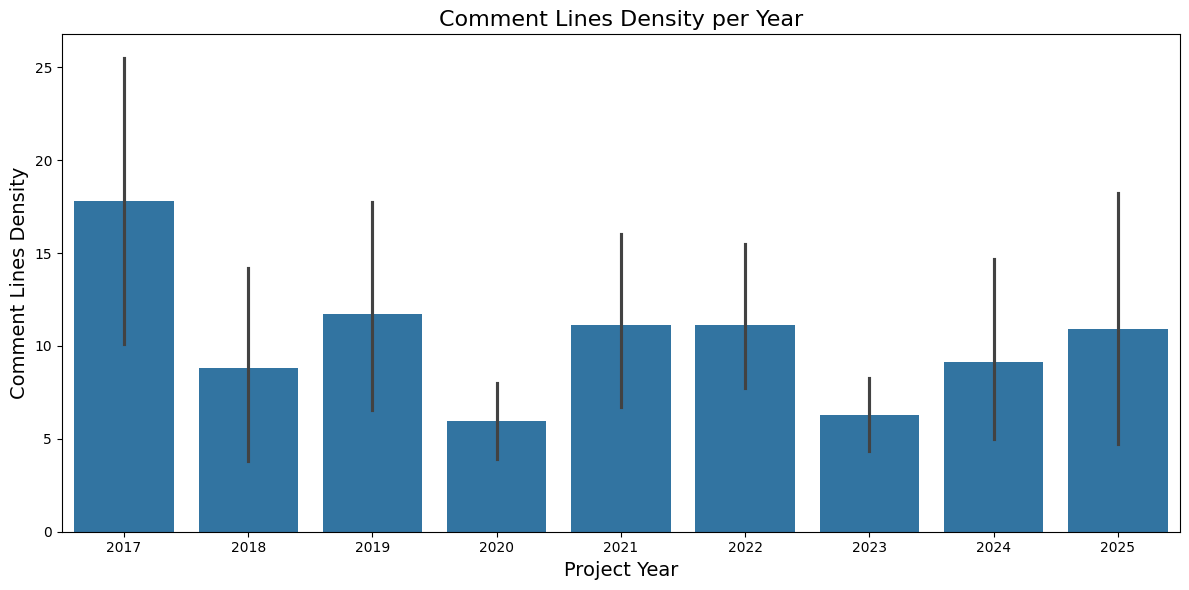

In [11]:
# COmment lines densitiy plotted per year

sqp_df["date"] = pd.to_datetime(sqp_df["date"], utc=True)

# Sort so latest commit is last
sqp_df_sorted = sqp_df.sort_values(["repository_id", "date"])

# Keep ONLY the last snapshot per repo
sqp_final_product = (
    sqp_df_sorted
    .groupby("repository_id")
    .tail(1)
    .reset_index(drop=True)
)

display(sqp_final_product.head())

# bar chart of comment lines density per year
plt.figure(figsize=(12, 6))
sns.barplot(x="project_year", y="comment_lines_density", data=sqp_final_product)
plt.title("Comment Lines Density per Year", fontsize=16)
plt.xlabel("Project Year", fontsize=14)
plt.ylabel("Comment Lines Density", fontsize=14)
plt.tight_layout()
plt.show()

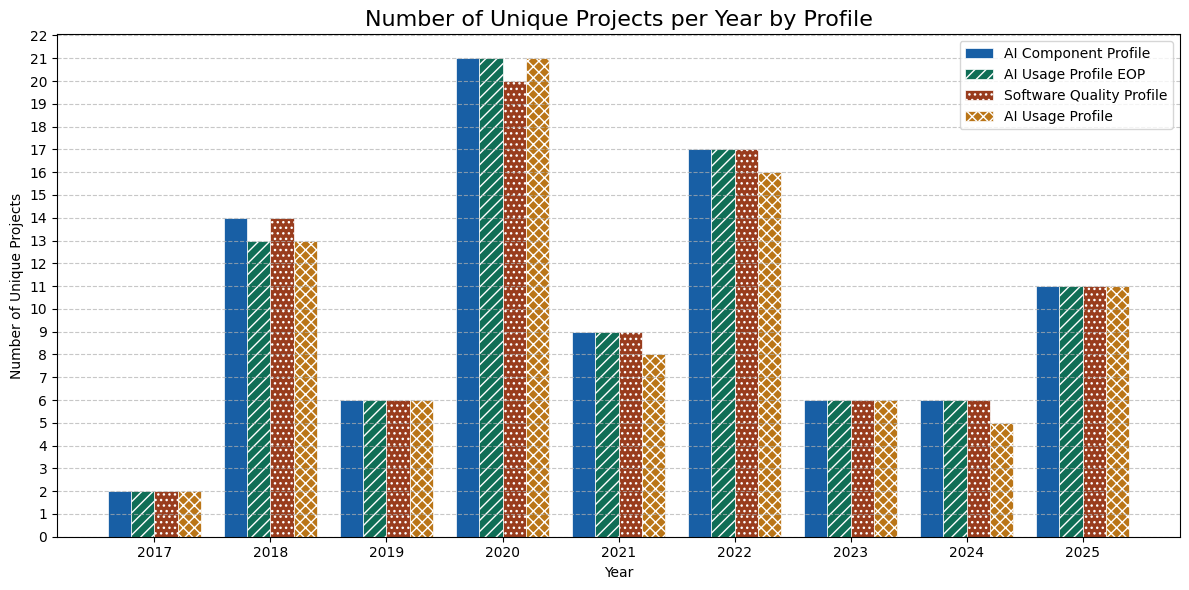

In [12]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

# Data
datasets = {
    'AI Component Profile': projects_per_year_aicp,
    'AI Usage Profile EOP': projects_per_year_aiup_eop,
    'Software Quality Profile': projects_per_year_sqp,
    'AI Usage Profile': projects_per_year_aiup,
}

# B&W accessible styles: distinct hatches + greyscale fills
styles = [
    {'color': '#185FA5', 'hatch': ''},       # blue
    {'color': '#0F6E56', 'hatch': '///'},     # vermillion
    {'color': '#993C1D', 'hatch': '...'},     # green
    {'color': "#BA7517", 'hatch': 'xxx'},     # pink
]

BUCKET_COLORS = ["#185FA5", "#0F6E56", "#993C1D", "#534AB7", "#BA7517", "#888780"]


# Align all years
all_years = sorted(set().union(*[d.index for d in datasets.values()]))
n_groups = len(all_years)
n_bars = len(datasets)
bar_width = 0.2
x = np.arange(n_groups)

for i, (label, data) in enumerate(datasets.items()):
    values = [data.get(year, 0) for year in all_years]
    ax.bar(
        x + i * bar_width,
        values,
        width=bar_width,
        label=label,
        color=styles[i]['color'],
        hatch=styles[i]['hatch'],
        edgecolor='white',
        linewidth=0.5,
    )

# Discrete y-axis
max_val = max(v for d in datasets.values() for v in d.values)
ax.set_yticks(range(0, int(max_val) + 2))

ax.set_xticks(x + bar_width * (n_bars - 1) / 2)
ax.set_xticklabels(all_years)
ax.set_title('Number of Unique Projects per Year by Profile', fontsize=16)
ax.set_xlabel('Year')
ax.set_ylabel('Number of Unique Projects')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("overleaf/projects_per_file.pdf", format="pdf")
plt.show()


In [13]:
sqp_df["date"] = pd.to_datetime(sqp_df["date"], utc=True)

# Sort so latest commit is last
sqp_df_sorted = sqp_df.sort_values(["repository_id", "date"])

# Keep ONLY the last snapshot per repo
sqp_final_product = (
    sqp_df_sorted
    .groupby("repository_id")
    .tail(1)
    .reset_index(drop=True)
)

print(sqp_final_product.columns)

Index(['repository_id', 'snapshot_commit', 'date', 'bugs', 'classes',
       'code_smells', 'cognitive_complexity', 'comment_lines',
       'comment_lines_density', 'complexity', 'coverage', 'duplicated_blocks',
       'duplicated_files', 'duplicated_lines', 'duplicated_lines_density',
       'files', 'functions', 'lines', 'lines_to_cover', 'ncloc', 'open_issues',
       'reliability_rating', 'reliability_remediation_effort',
       'security_hotspots', 'security_rating', 'security_remediation_effort',
       'security_review_rating', 'sqale_debt_ratio', 'sqale_index',
       'sqale_rating', 'statements', 'tests', 'uncovered_lines', 'violations',
       'vulnerabilities', 'n_blocker', 'n_critical', 'n_major', 'n_minor',
       'n_info', 'n_security', 'n_reliability', 'n_maintainability',
       'n_consistent', 'n_intentional', 'n_adaptable', 'n_responsible',
       'total_issues_per_kloc', 'critical_plus_blocker_ratio', 'major_ratio',
       'minor_ratio', 'info_ratio', 'security_ratio

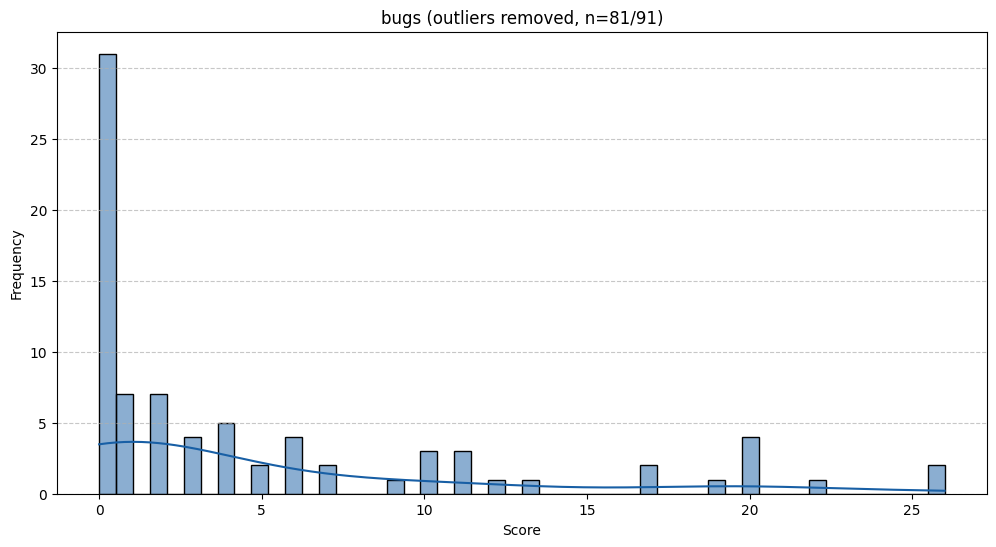

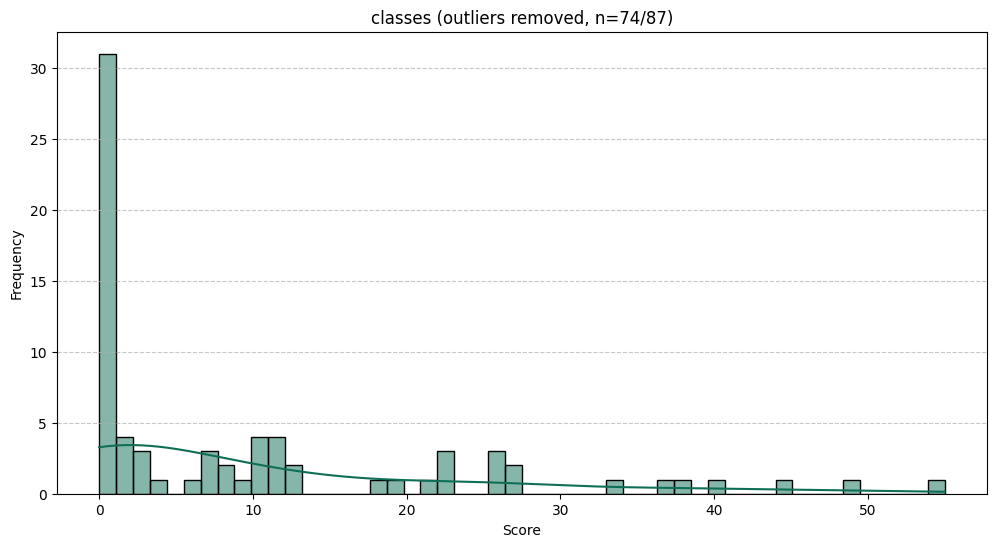

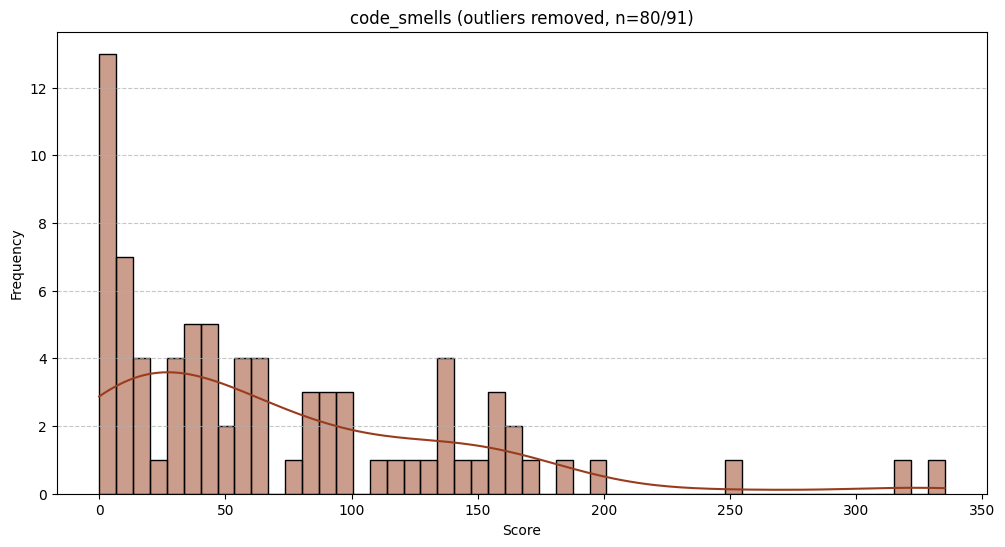

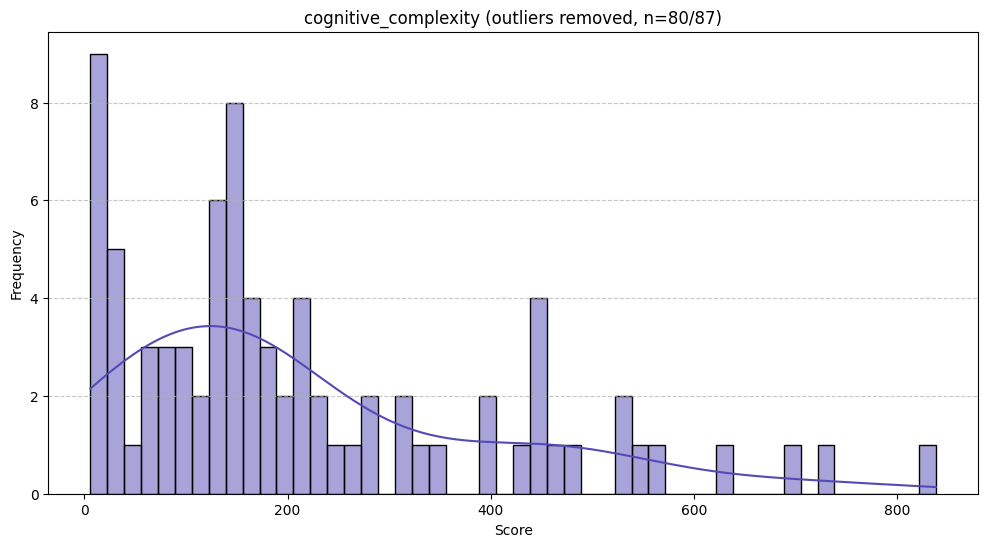

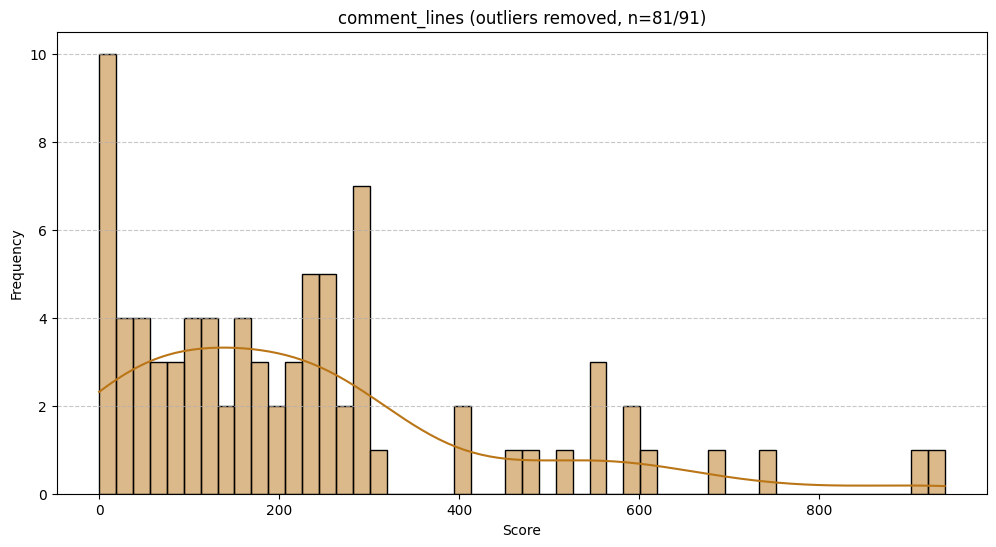

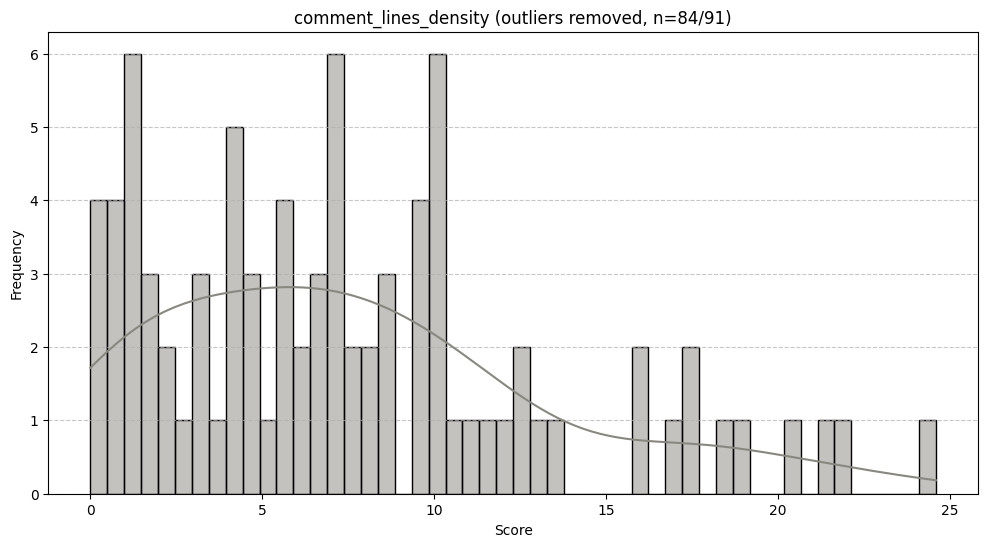

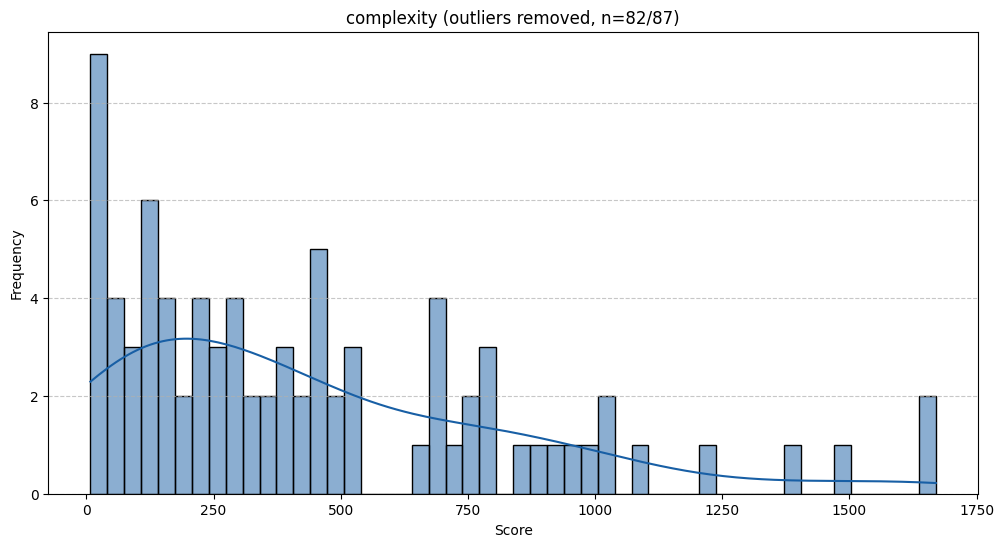

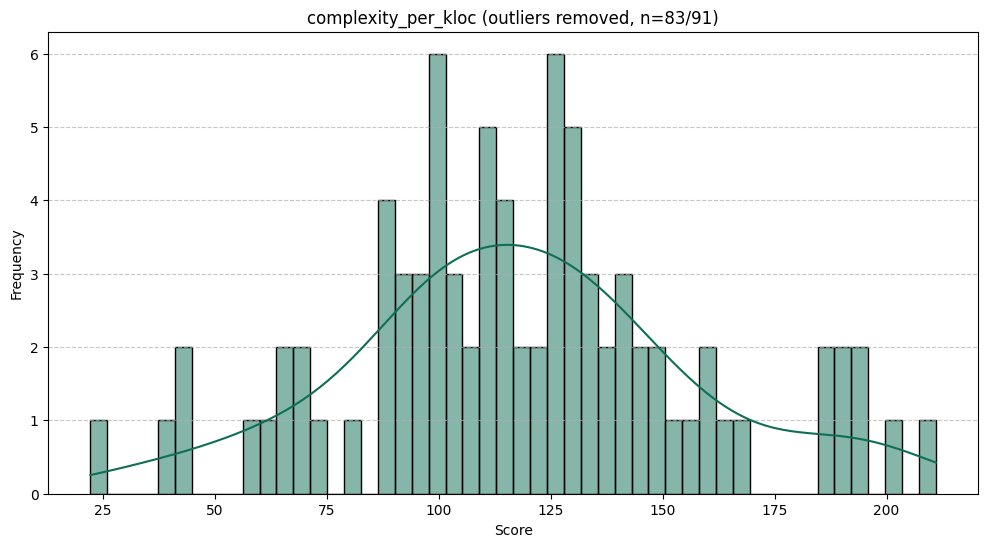

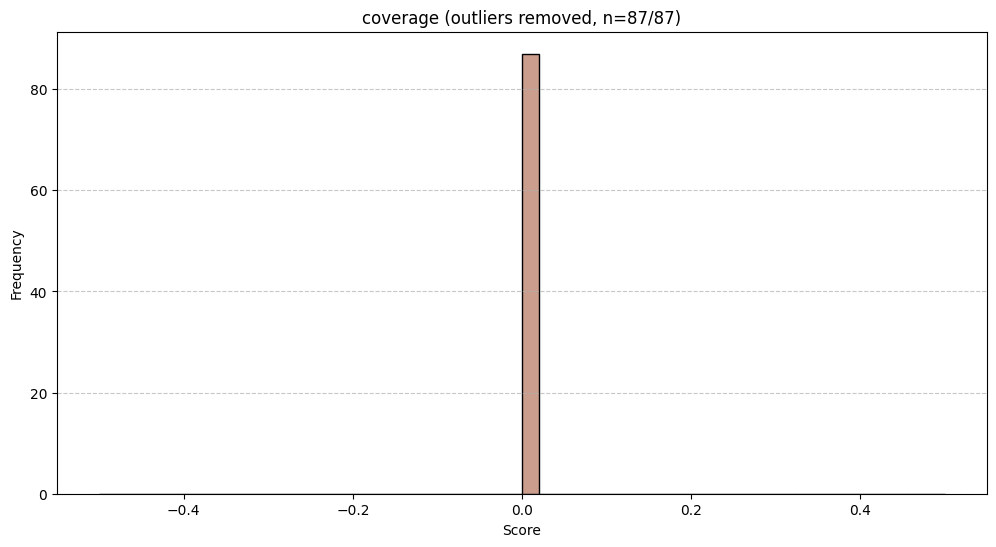

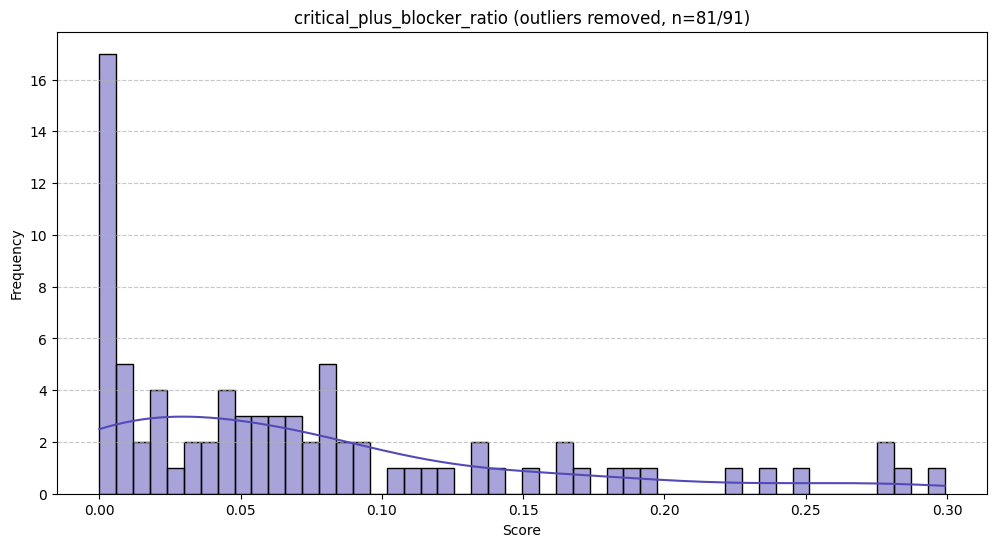

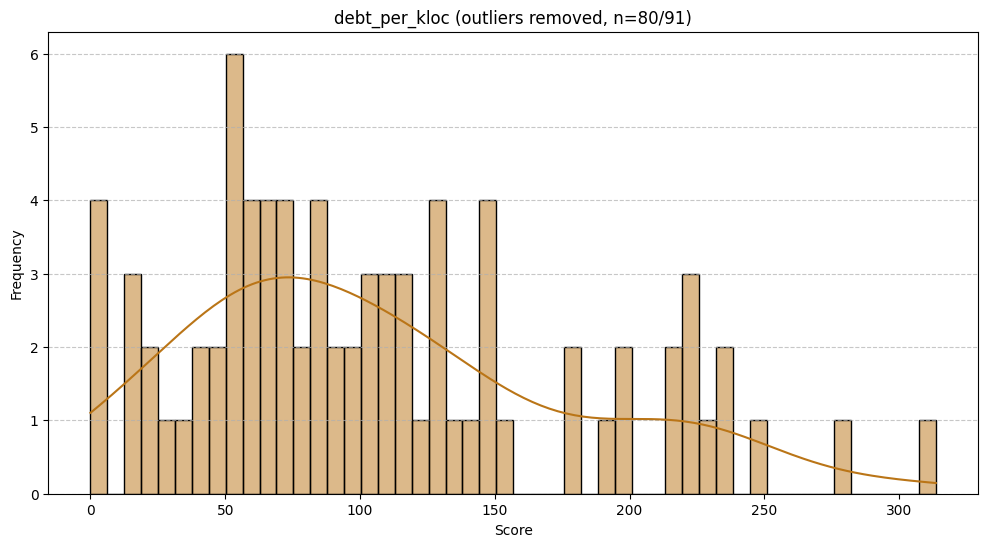

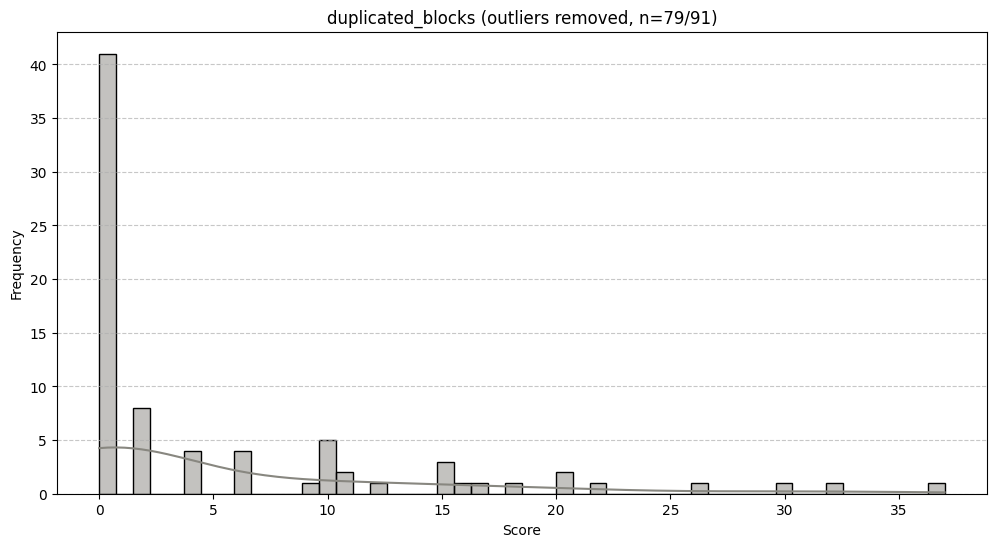

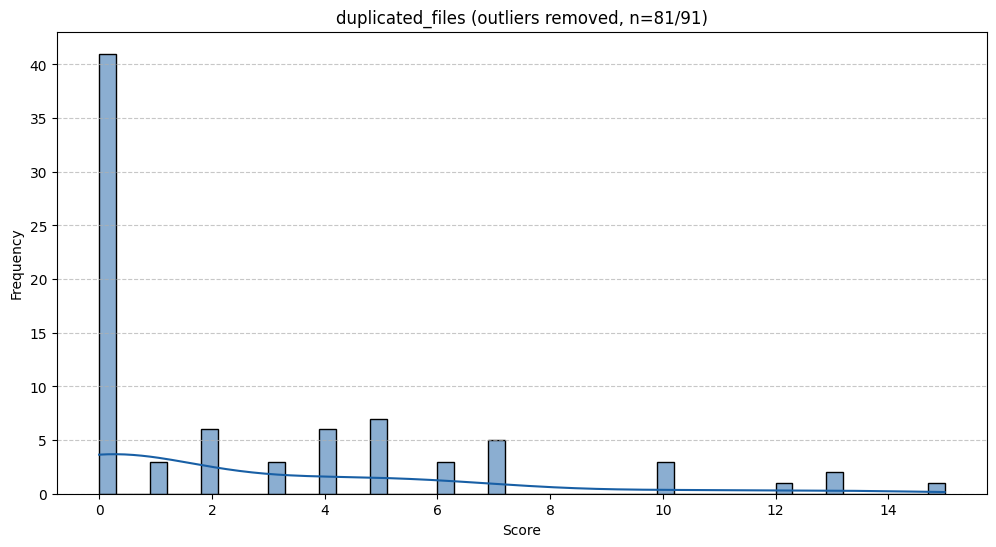

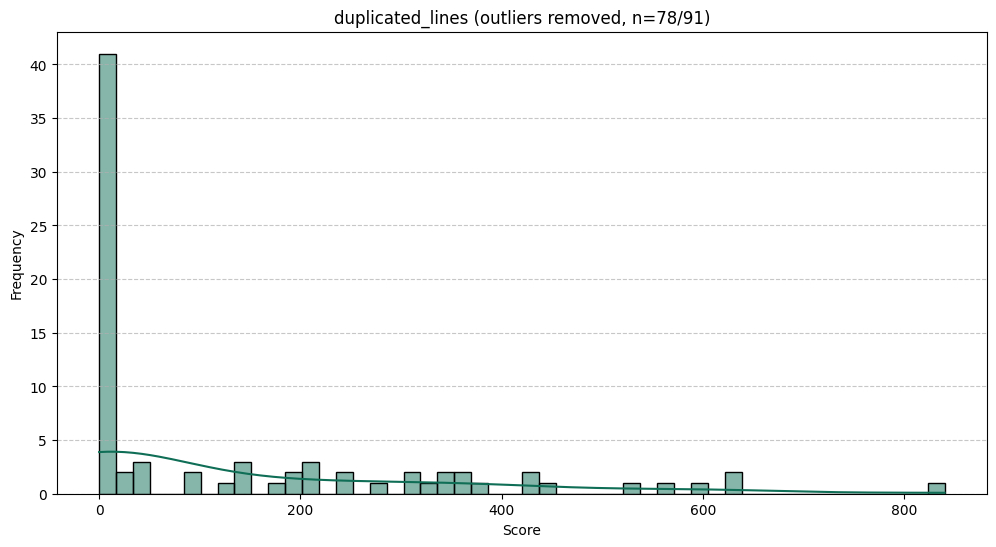

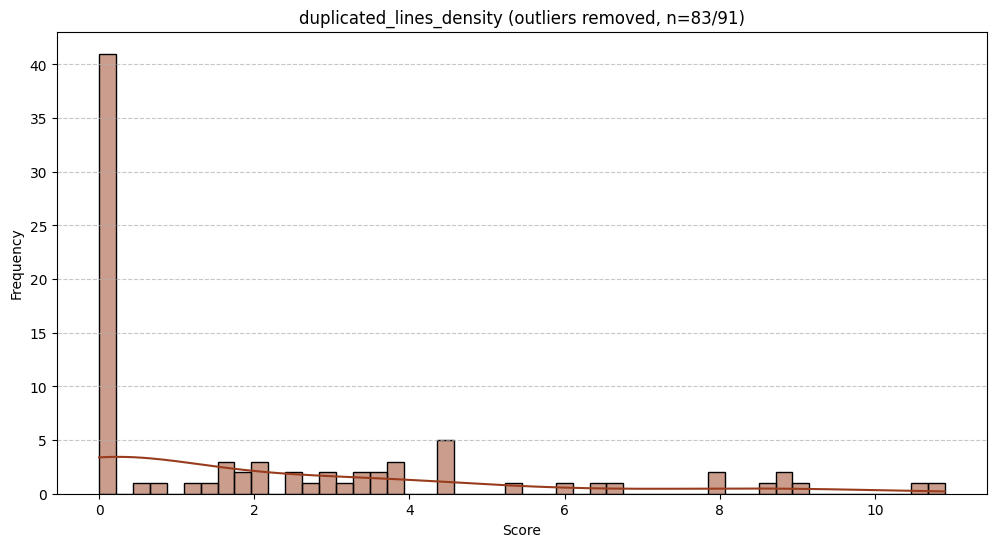

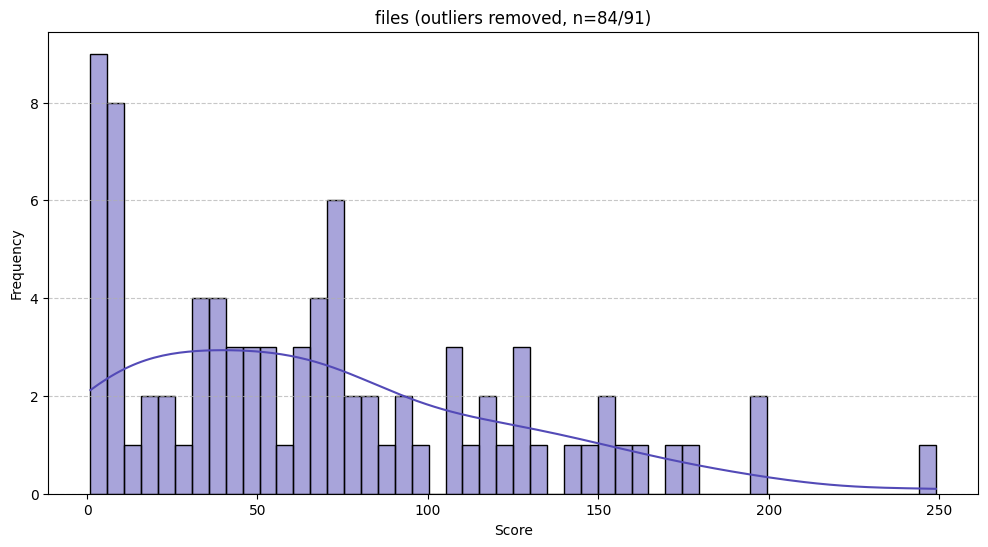

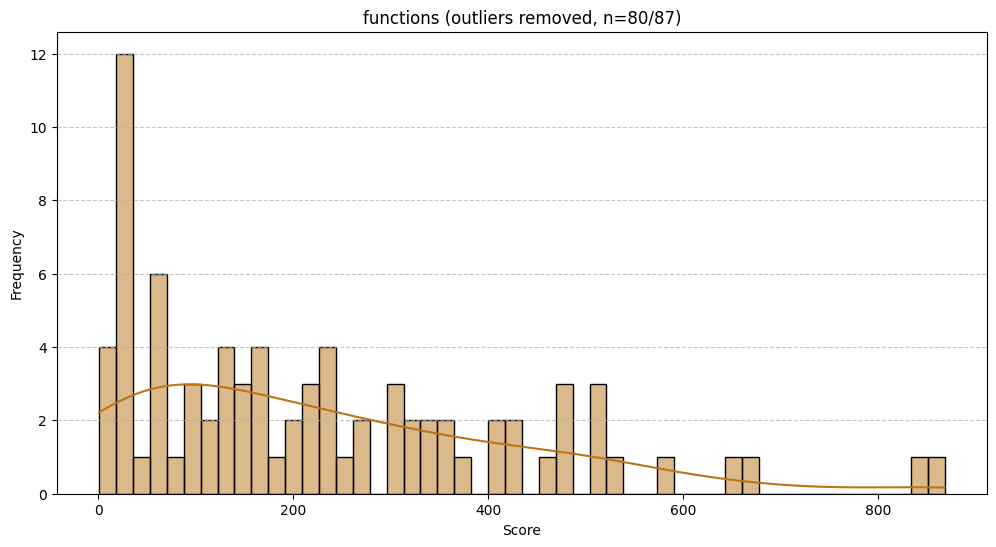

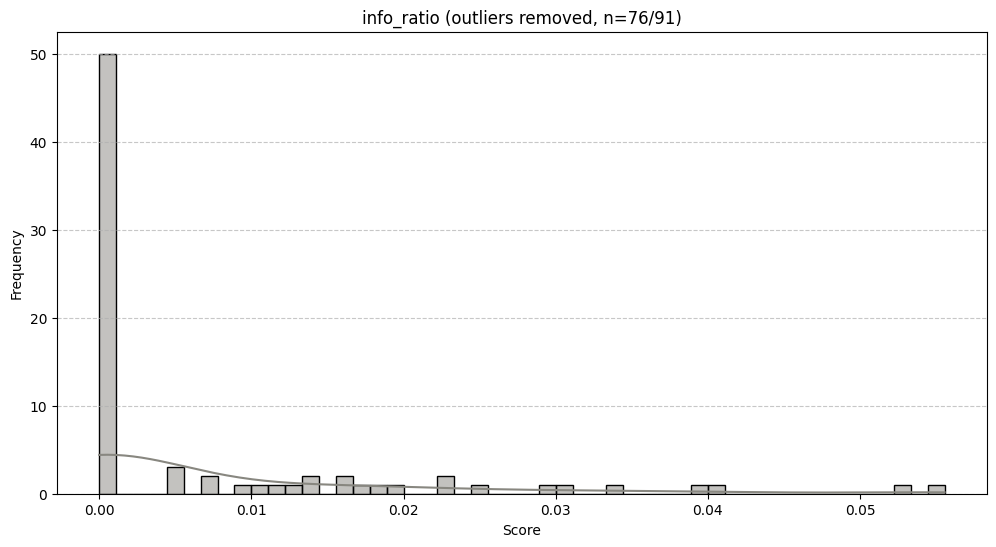

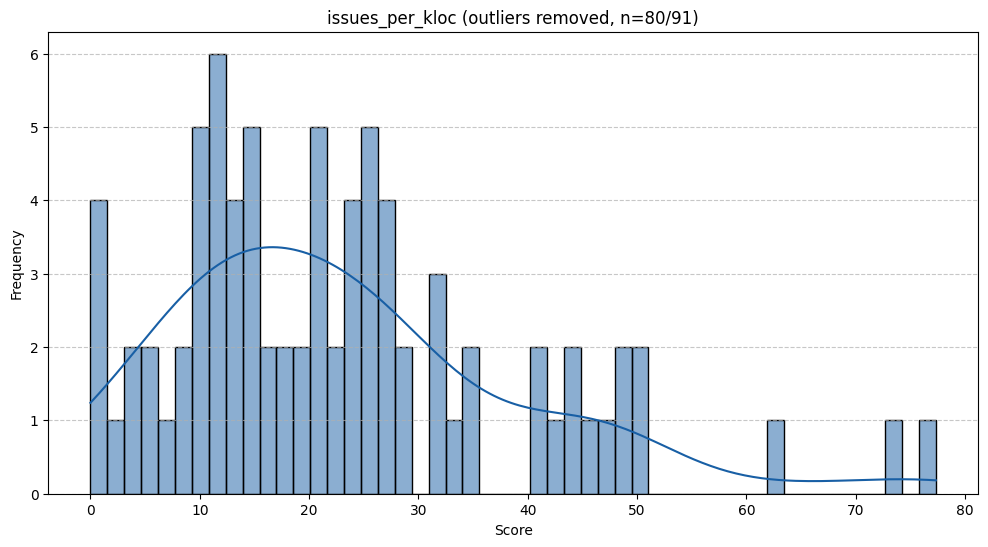

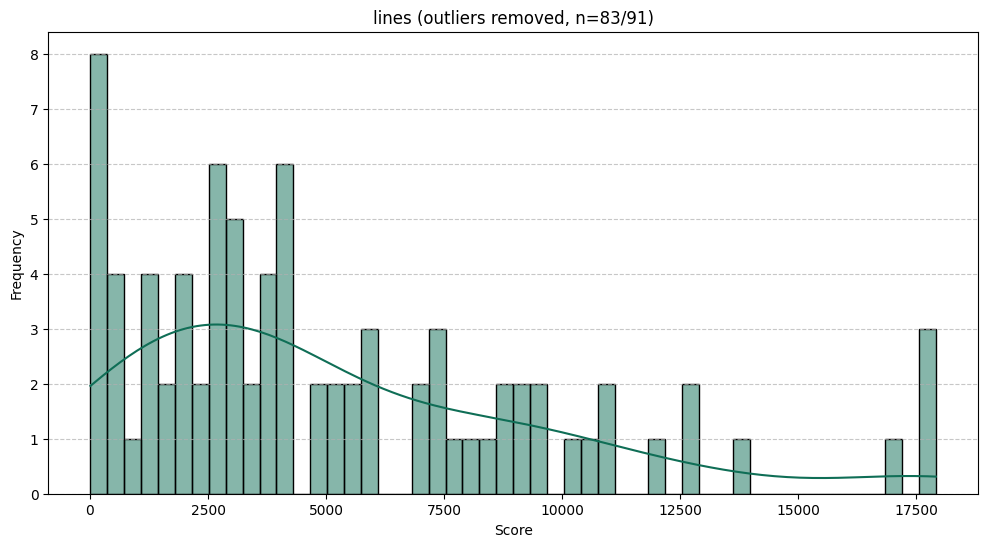

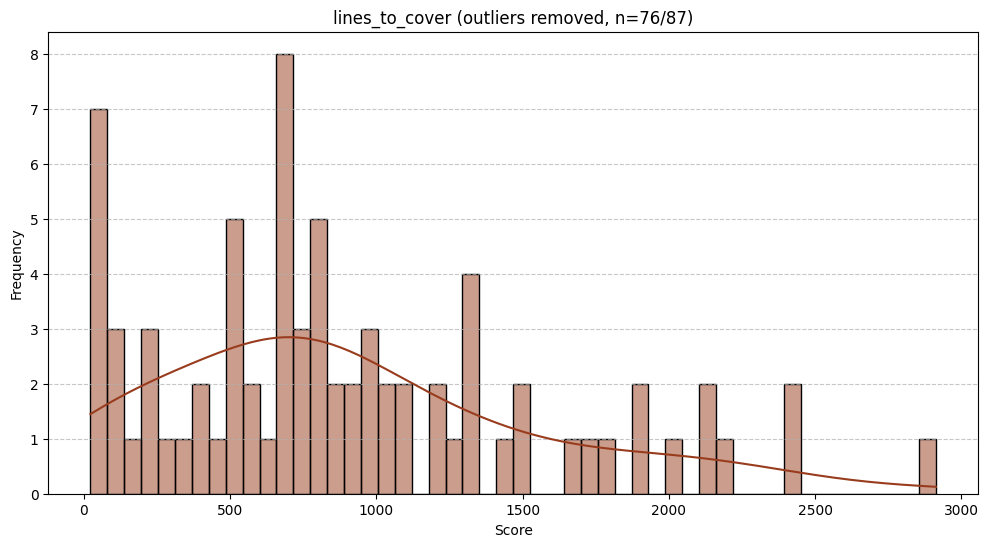

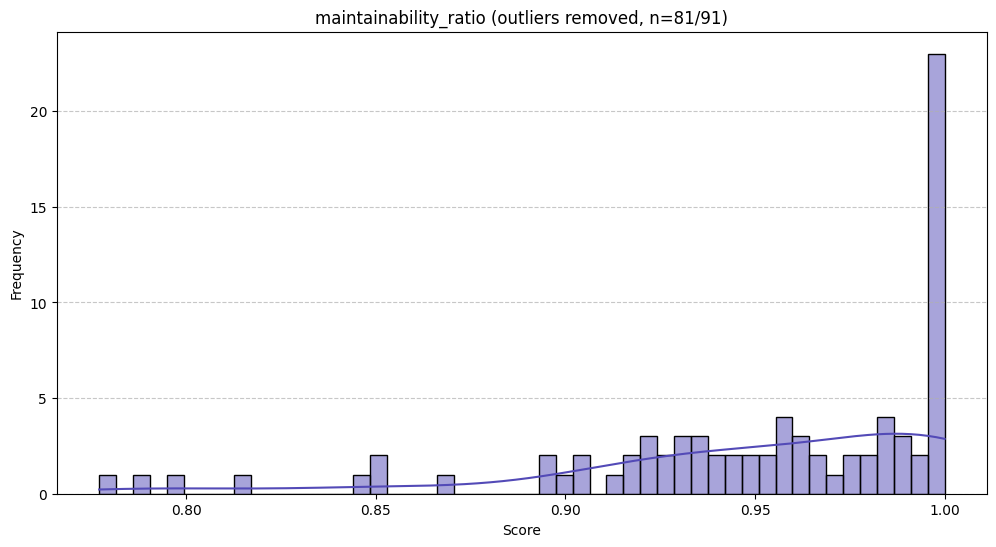

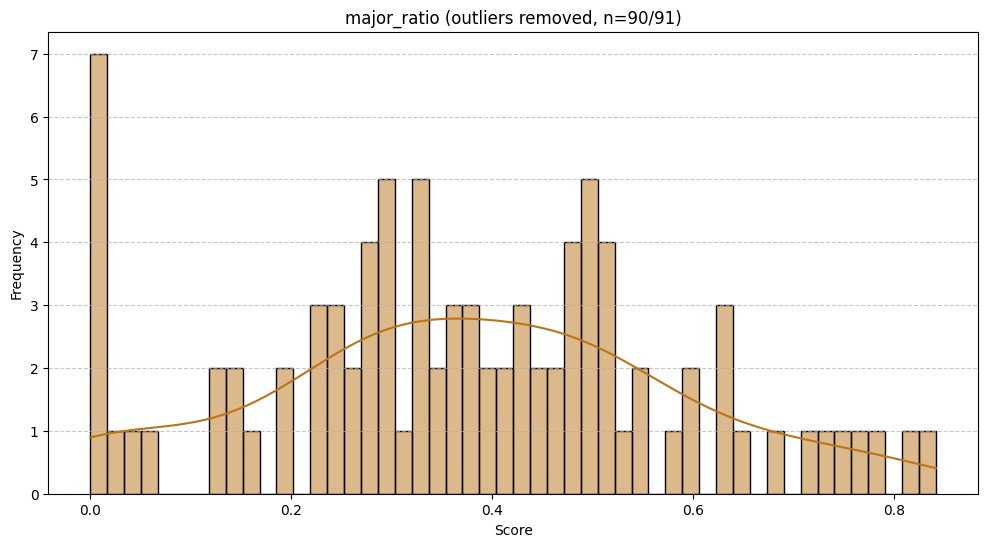

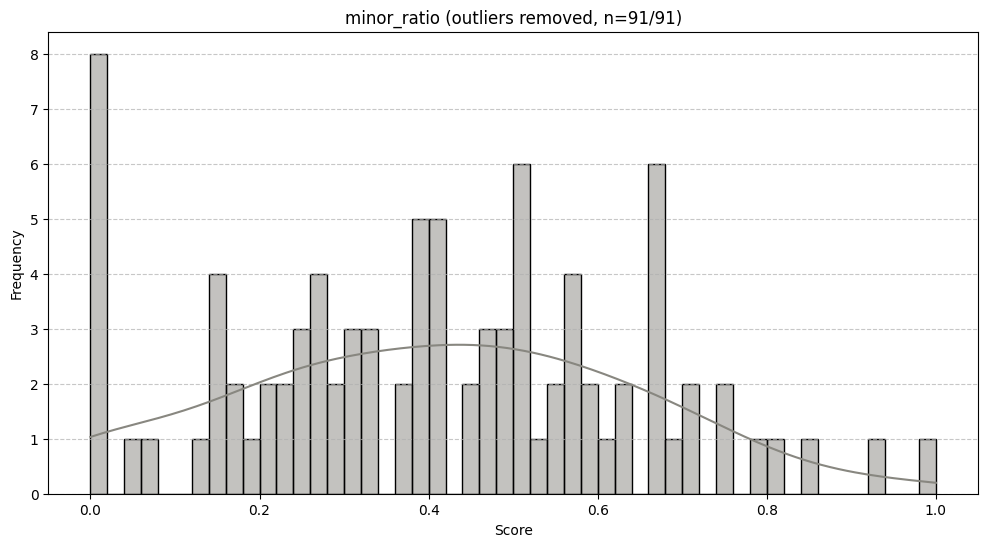

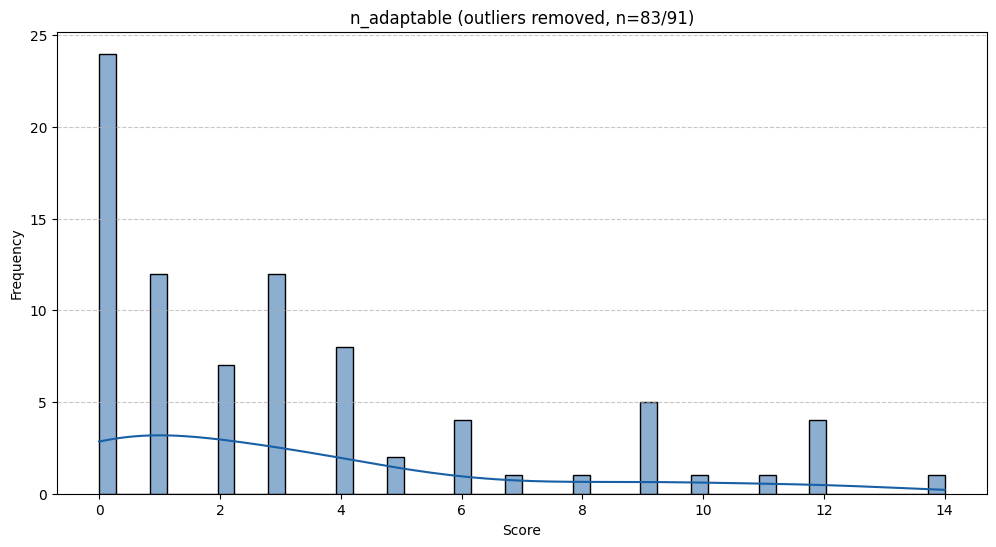

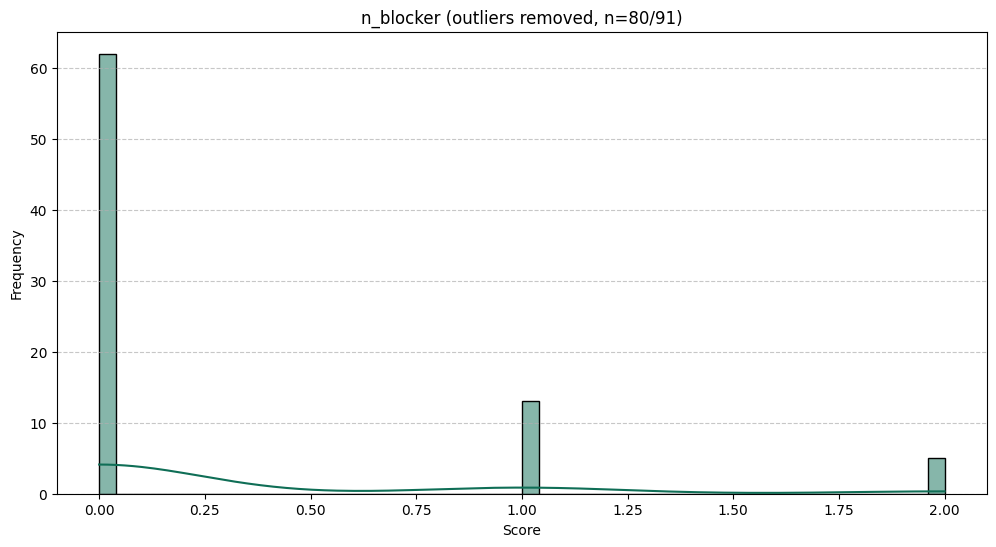

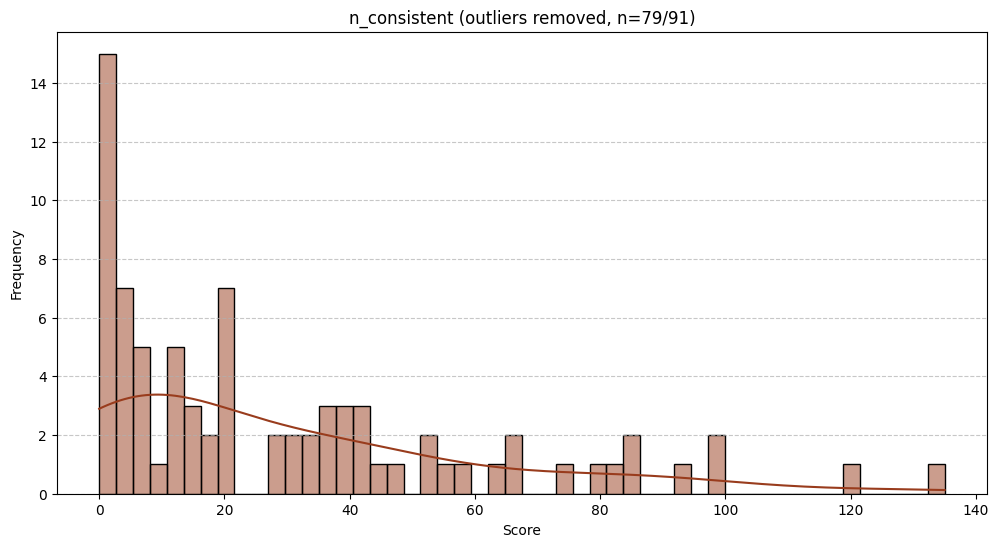

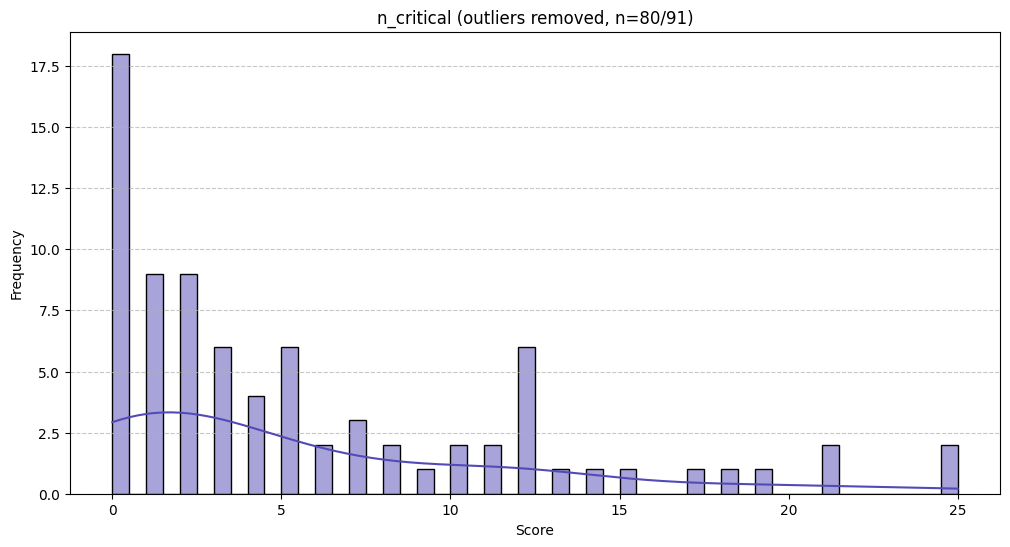

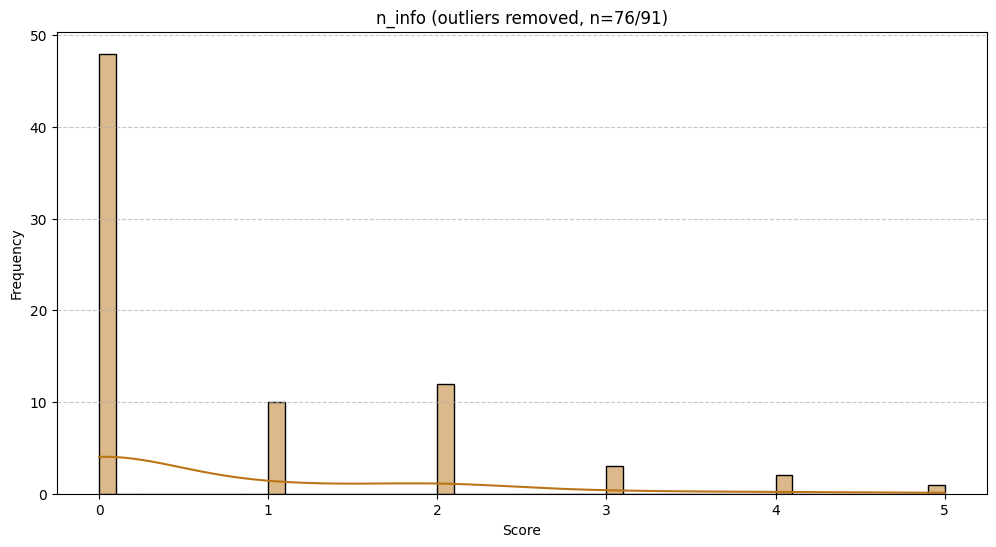

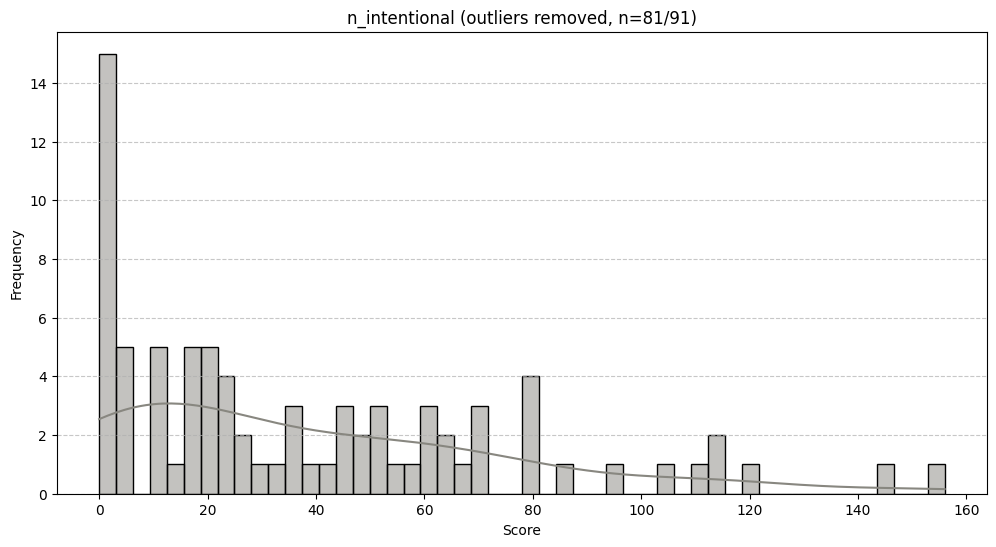

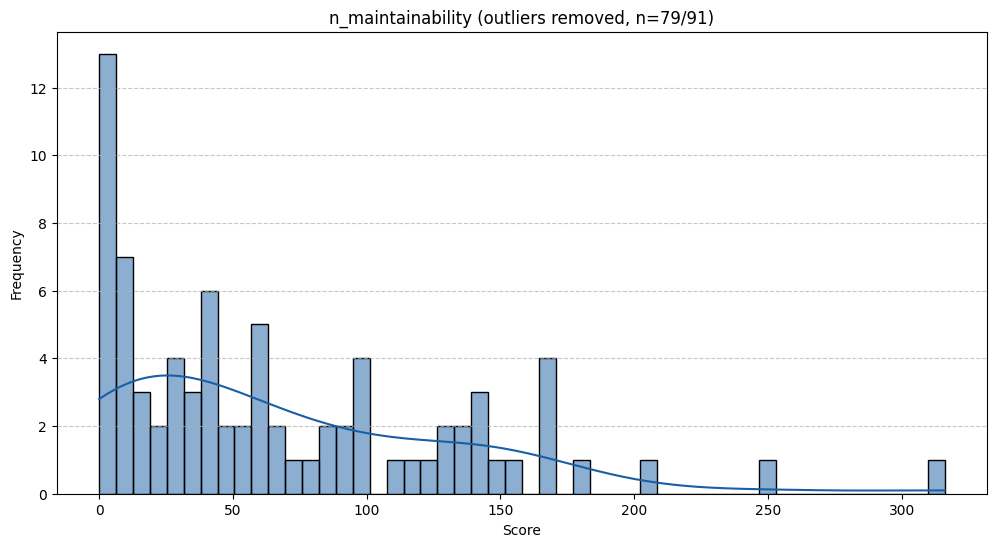

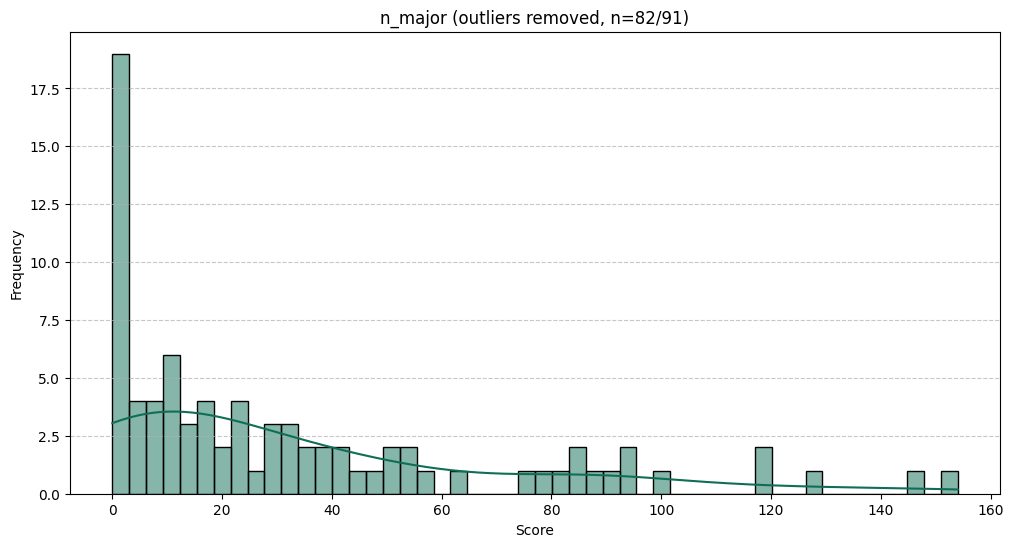

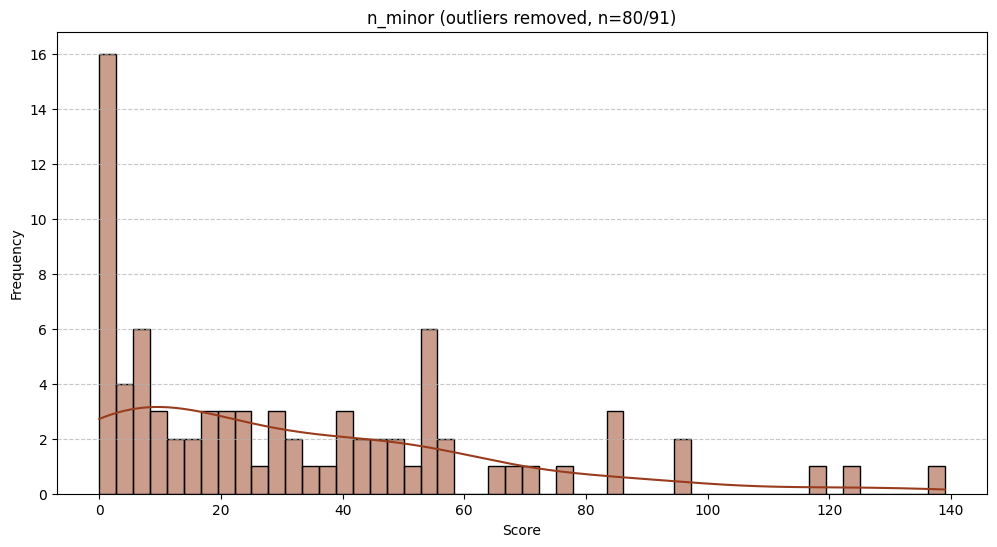

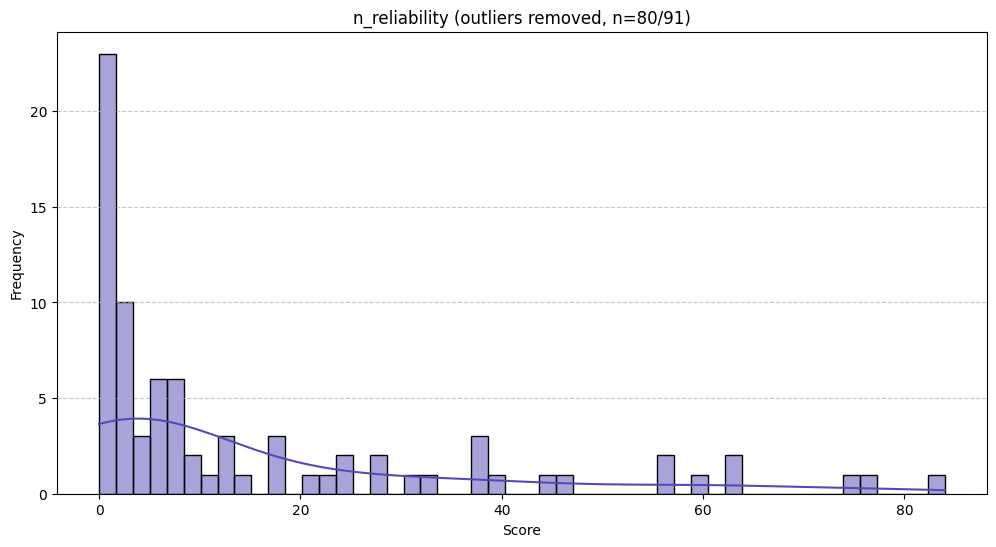

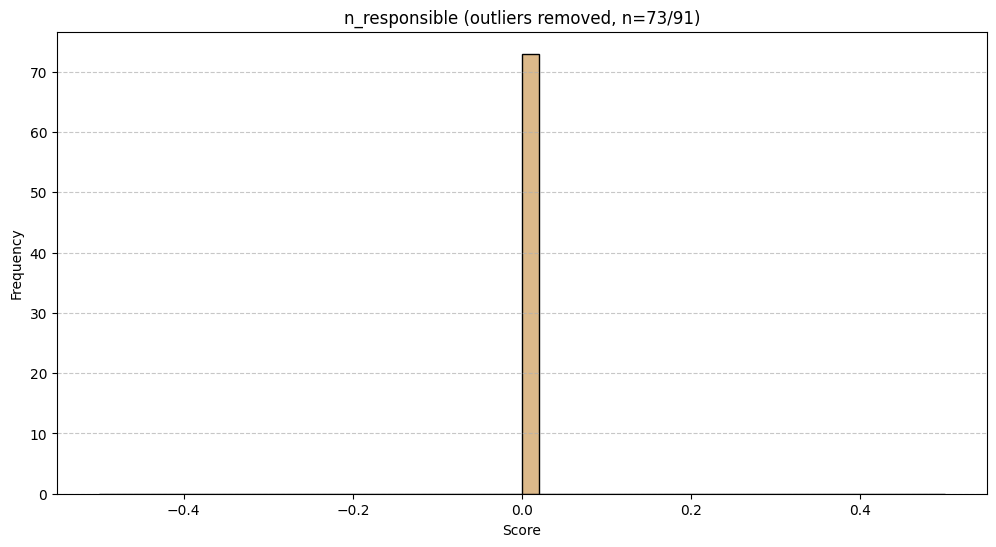

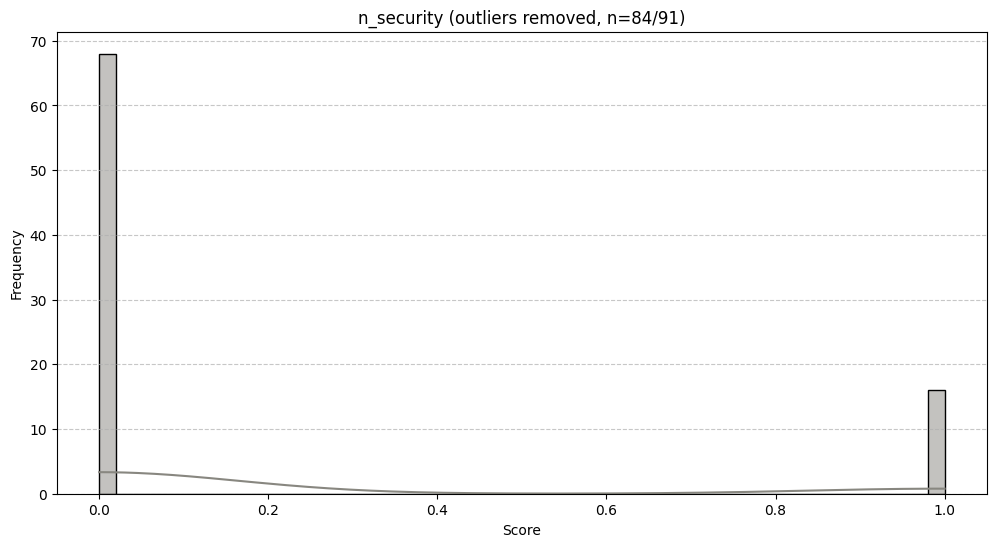

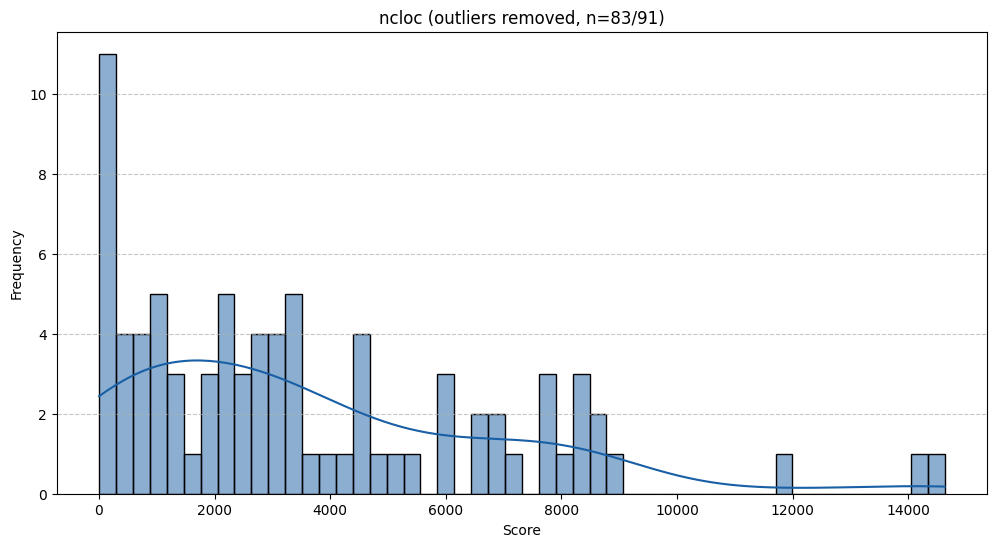

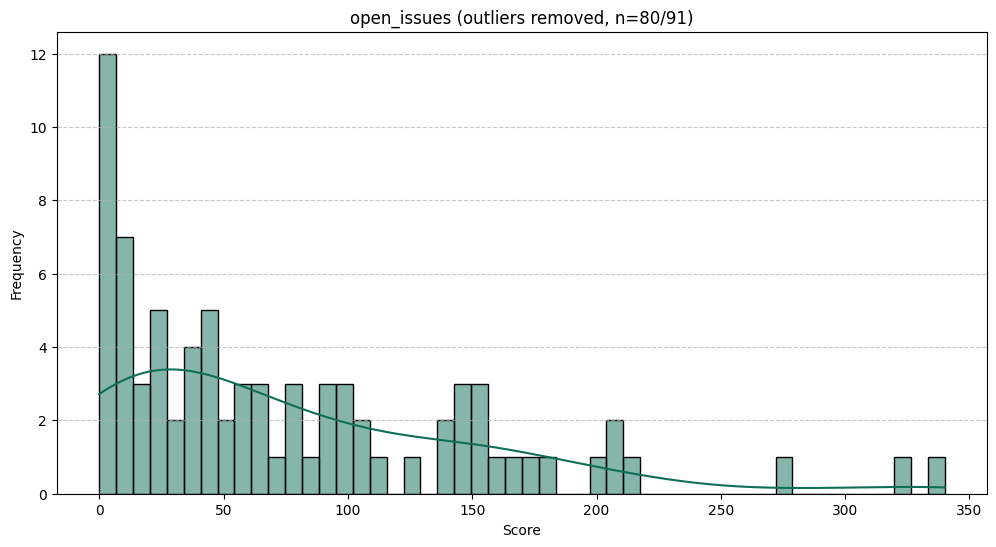

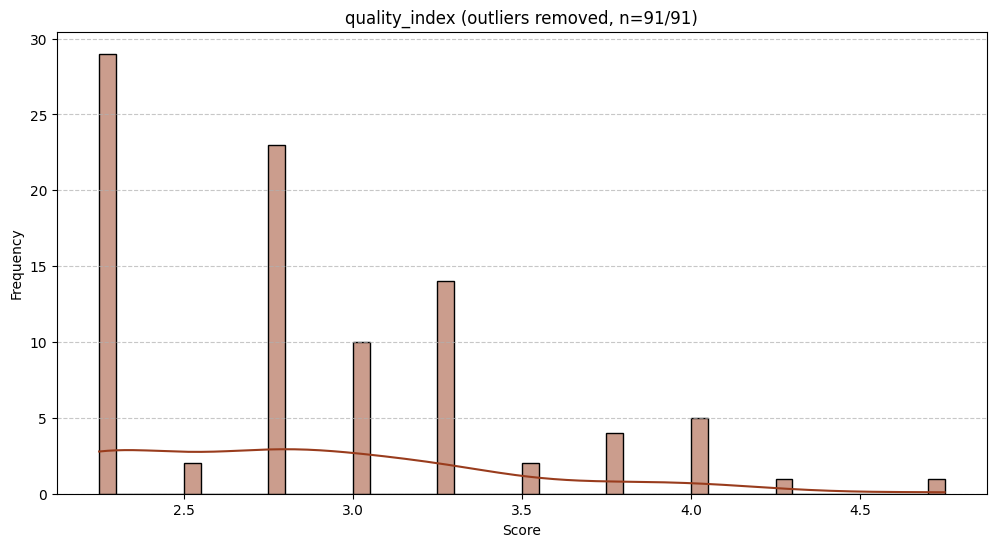

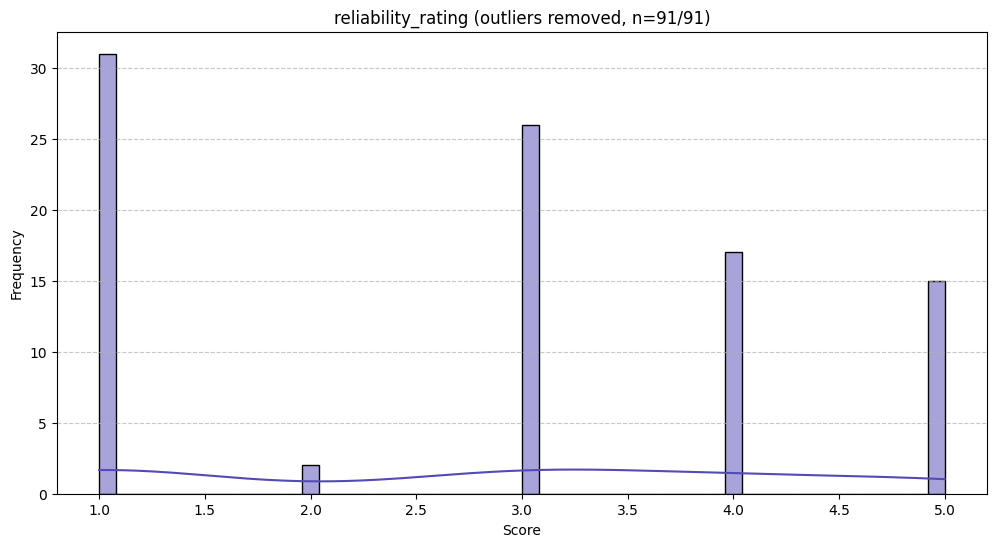

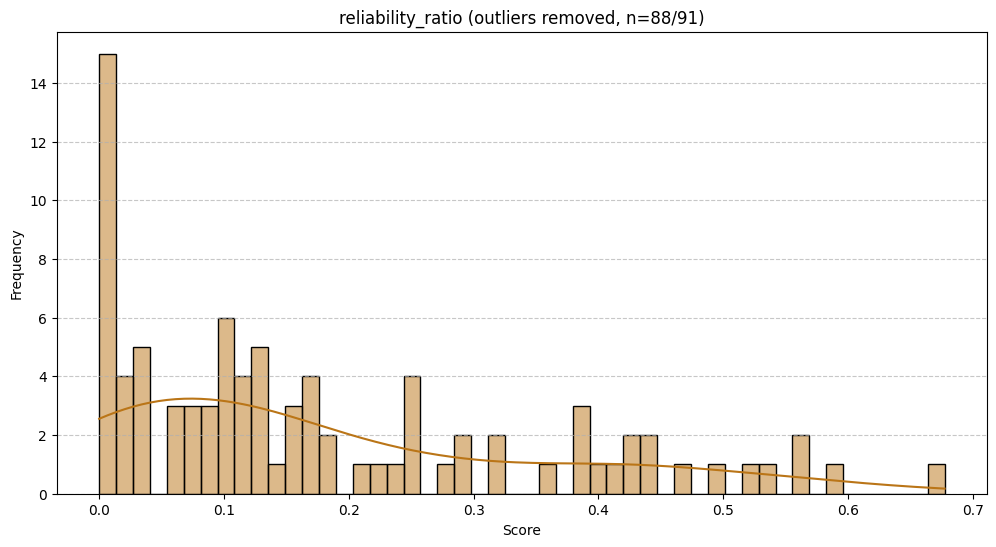

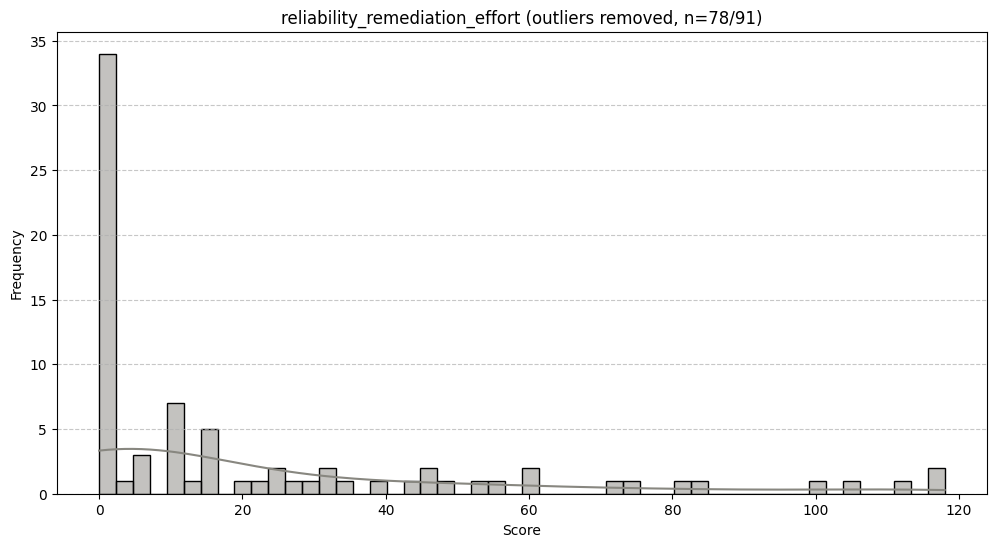

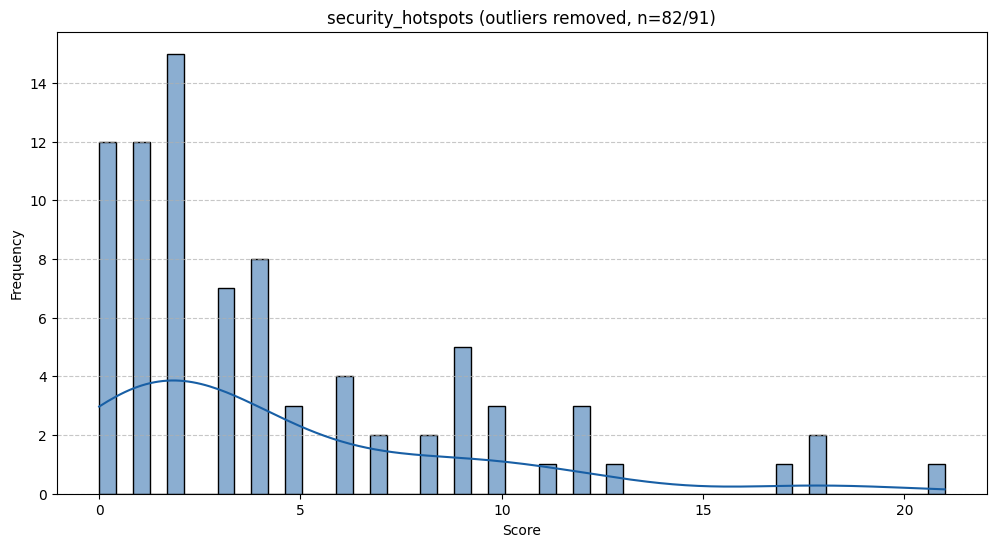

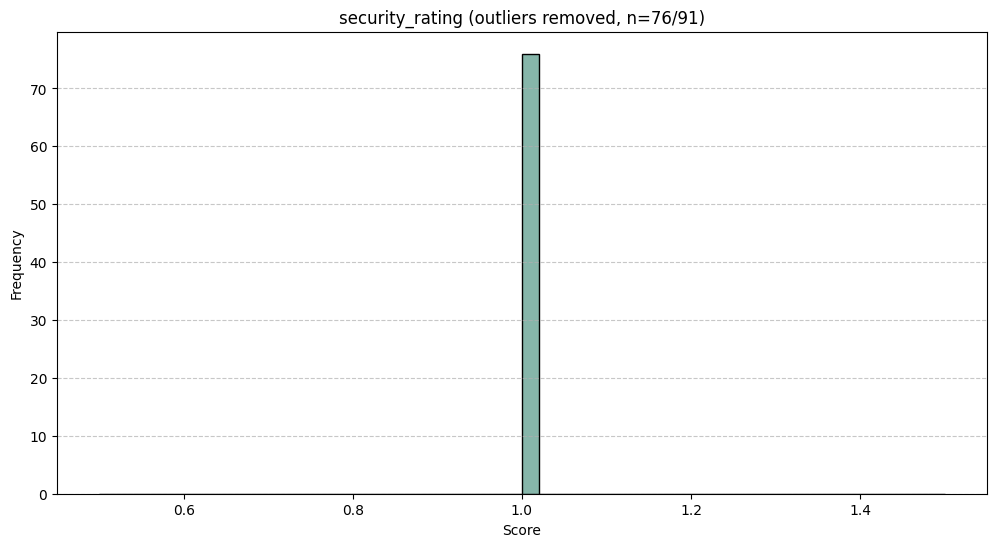

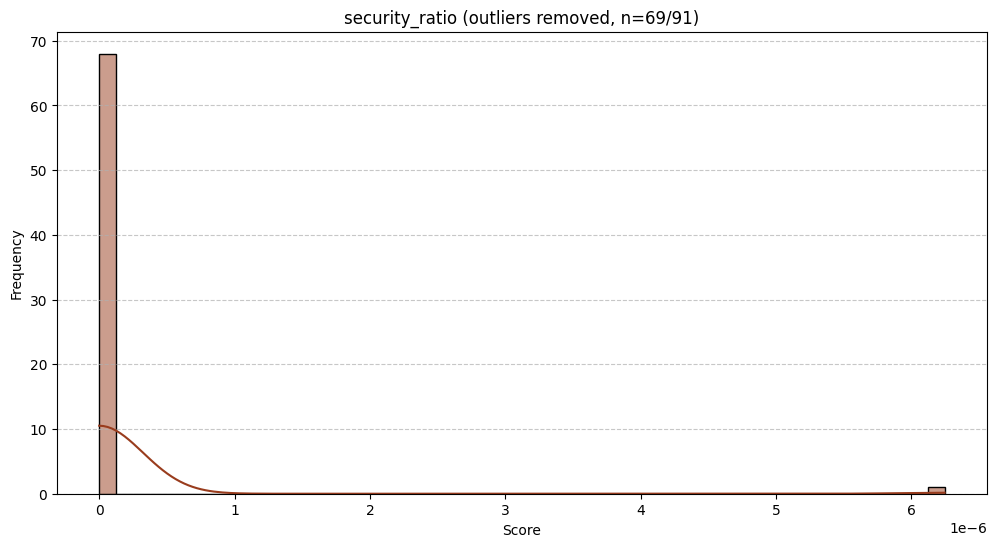

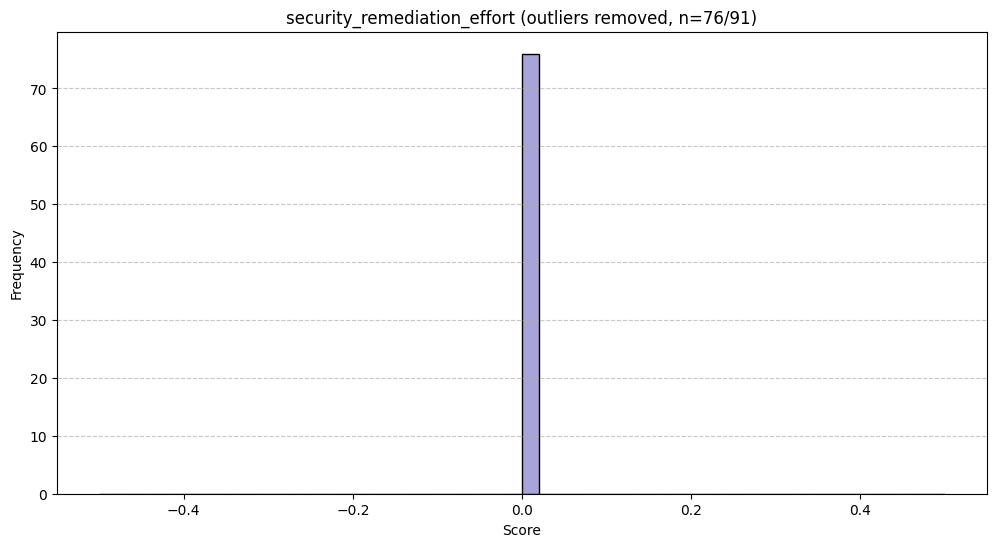

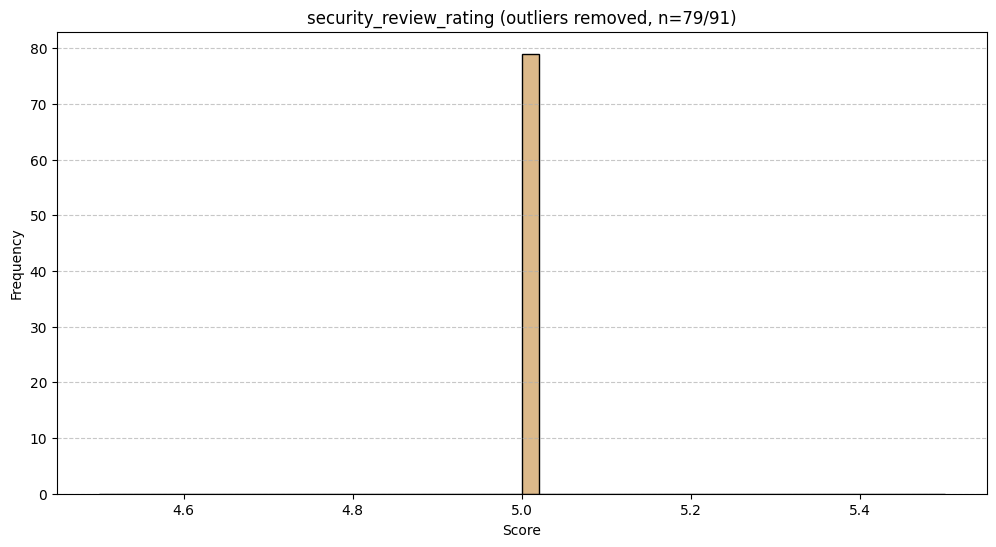

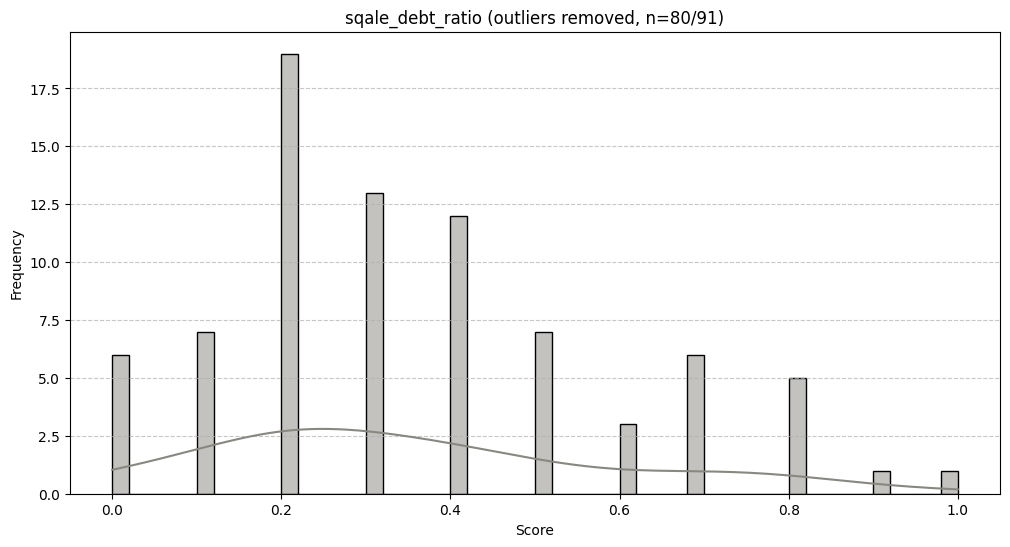

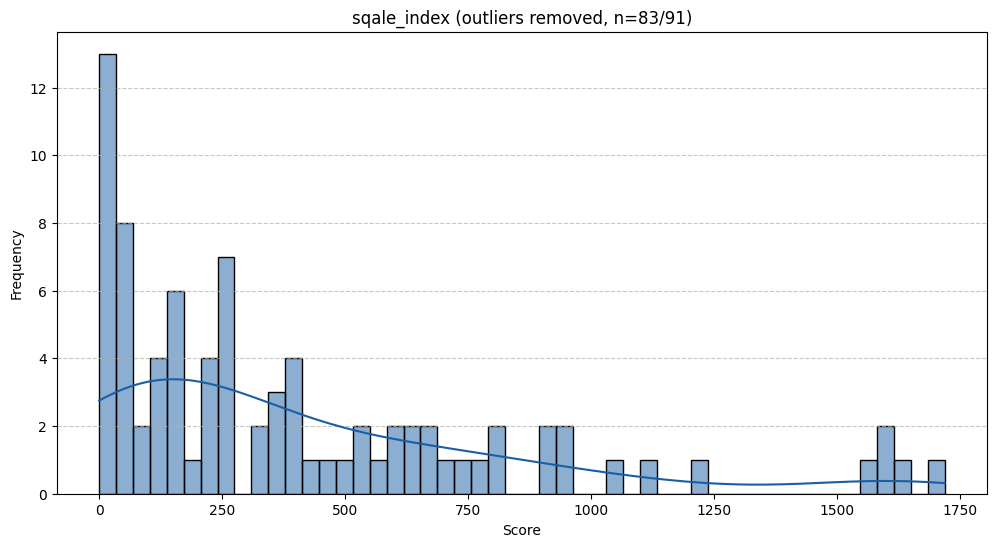

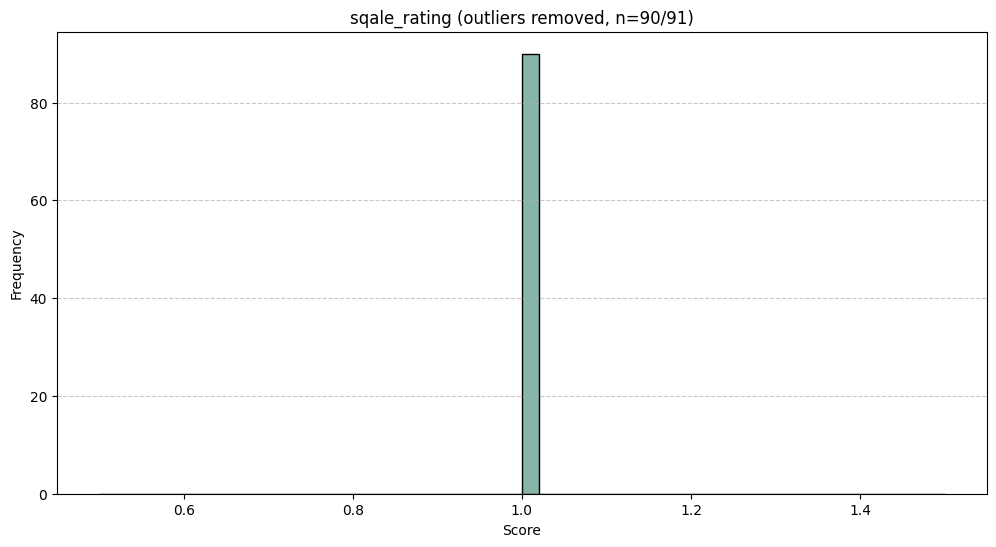

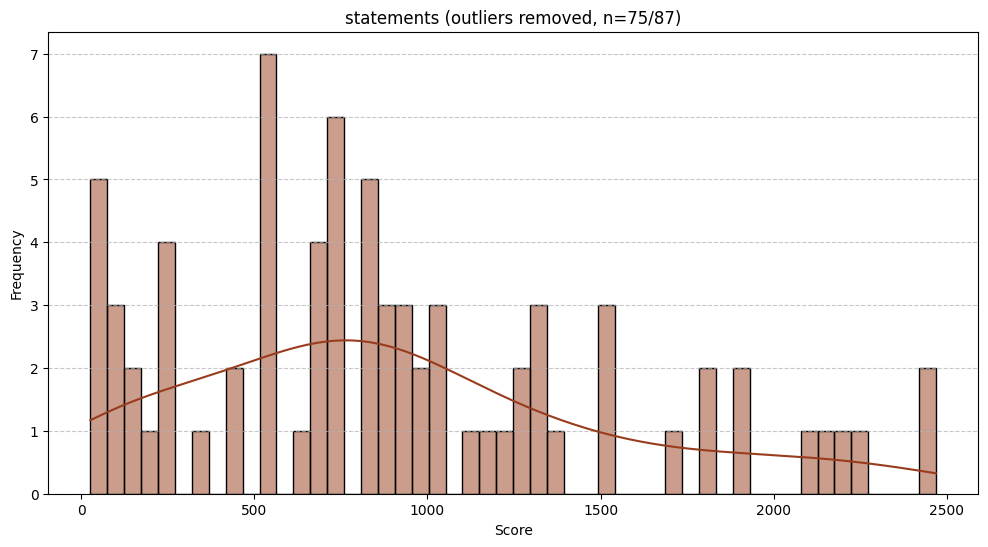

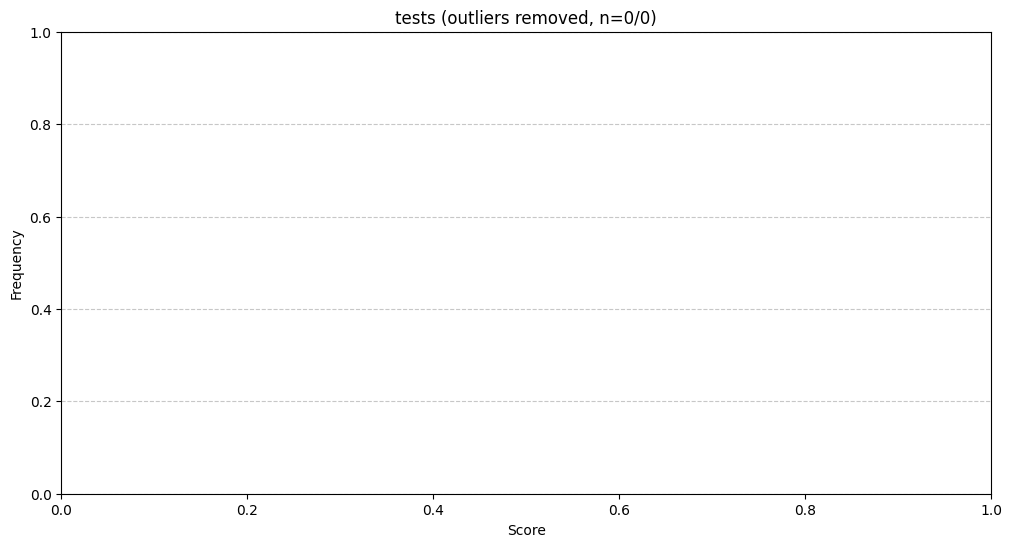

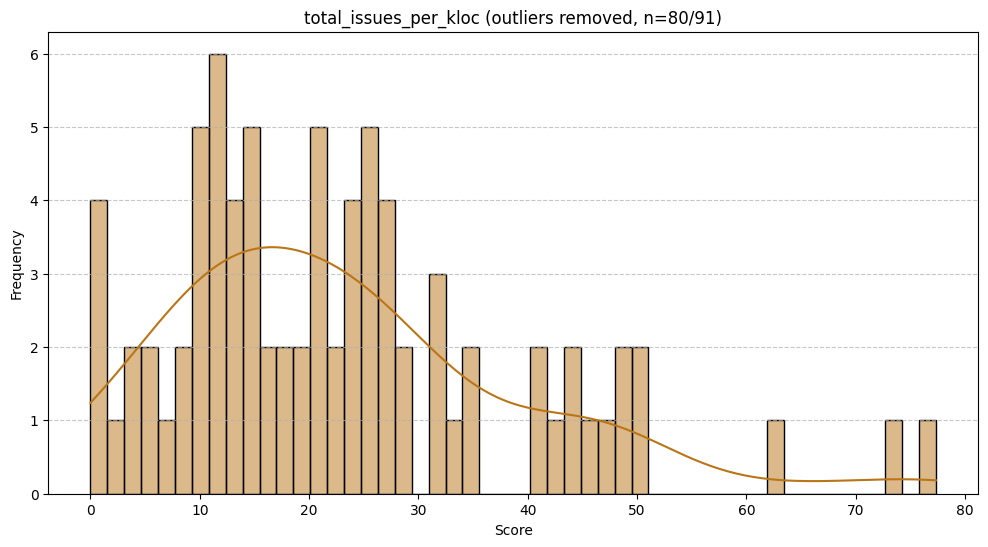

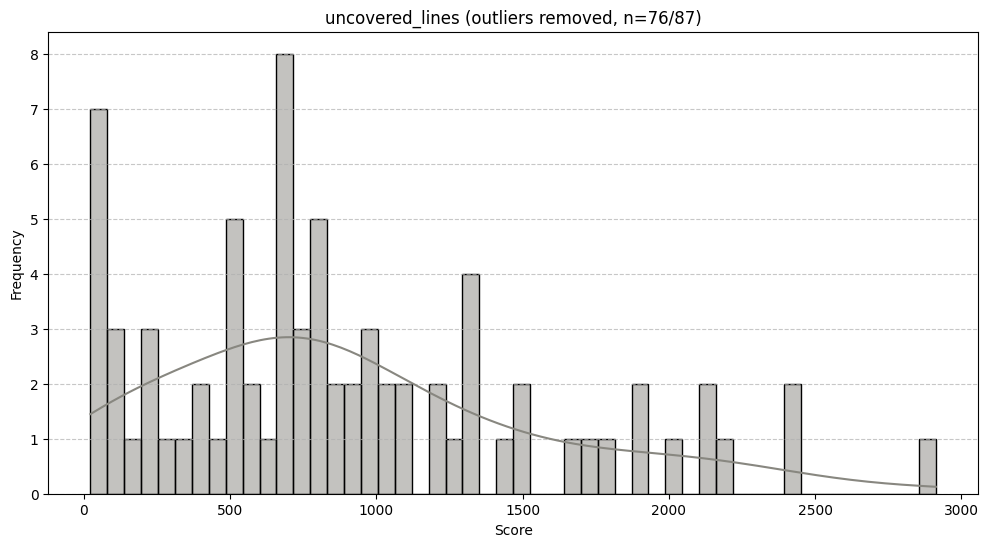

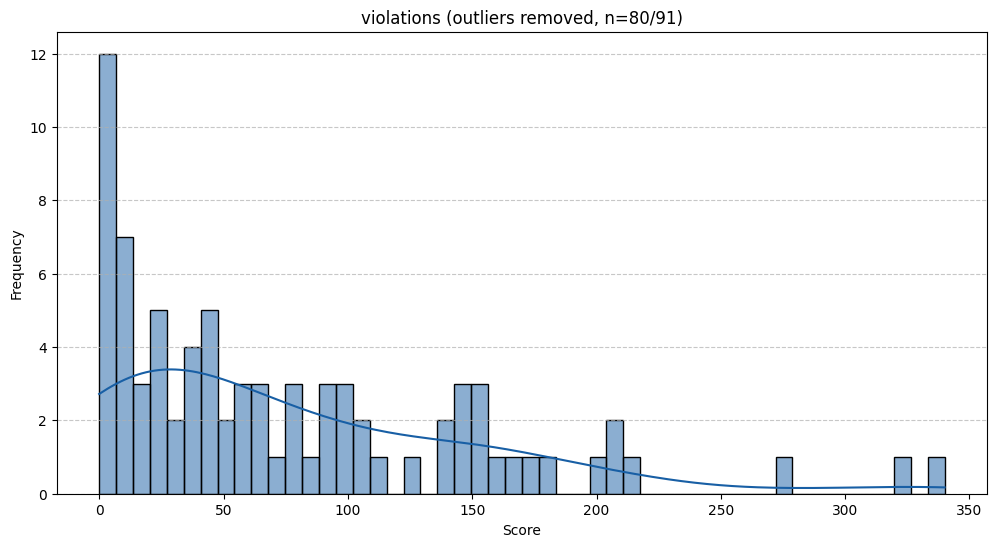

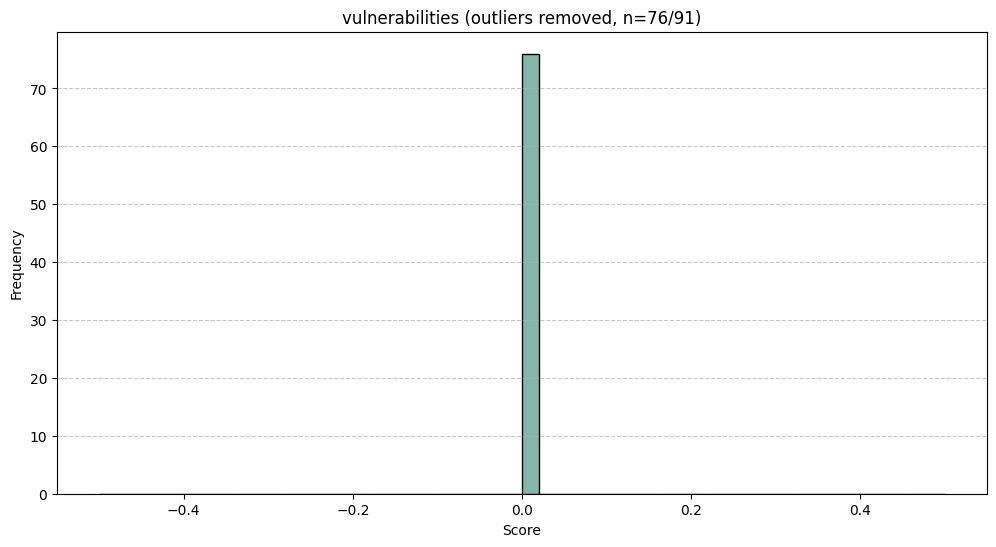

In [14]:
from scipy import stats

columns_to_plot = sqp_final_product.columns.difference(["repository_id", "snapshot_commit", "date", "project_year", "languages"])

for i, col in enumerate(columns_to_plot):
    data = sqp_final_product[col].dropna()
    
    # Remove outliers using IQR
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR = Q3 - Q1
    filtered = data[(data >= Q1 - 1.5 * IQR) & (data <= Q3 + 1.5 * IQR)]
    
    plt.figure(figsize=(12, 6))
    sns.histplot(filtered, bins=50, kde=True, color=BUCKET_COLORS[i % len(BUCKET_COLORS)])
    # Add a distribution line over
    
    plt.title(f'{col} (outliers removed, n={len(filtered)}/{len(data)})')
    plt.xlabel('Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.savefig(f'sqp/figure_{col}_distribution.png')
    plt.show()

AI Usage Profile columns to plot: Index(['ai_commit_ratio', 'ai_likelihood_std', 'author_prior_commits',
       'average_ai_file_prob', 'avg_loc_per_file', 'code_churn',
       'days_since_author_last_commit', 'high_ai_confidence_files',
       'loc_added', 'loc_deleted', 'n_active_devs_since_last_snapshot',
       'num_files_changed', 'prob_ai_whodunit', 'prob_human_droiddetect',
       'prob_human_whodunit', 'prob_machine_droiddetect',
       'prob_machine_generated_adversarial_droiddetect',
       'prob_machine_refined_droiddetect', 'whodunit_n_files'],
      dtype='str')


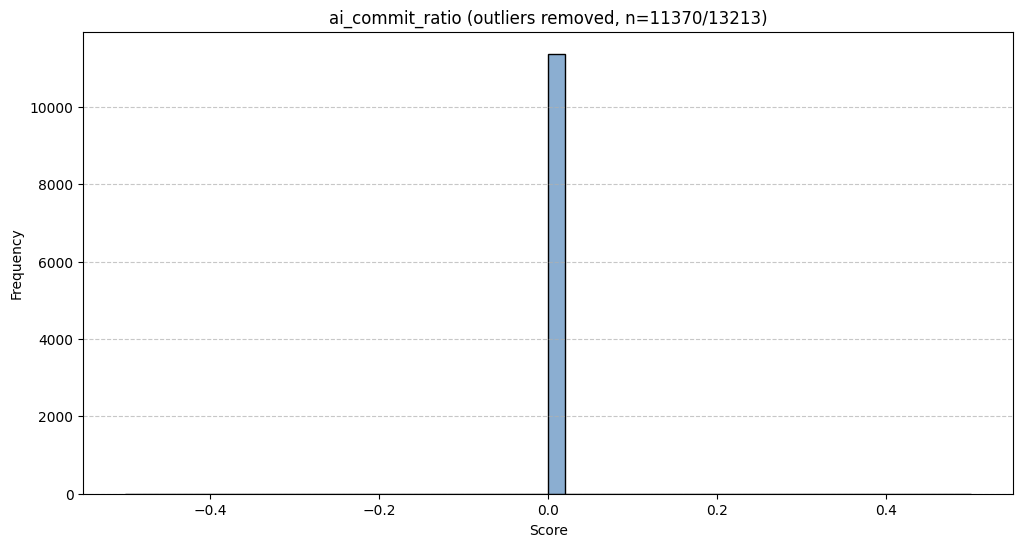

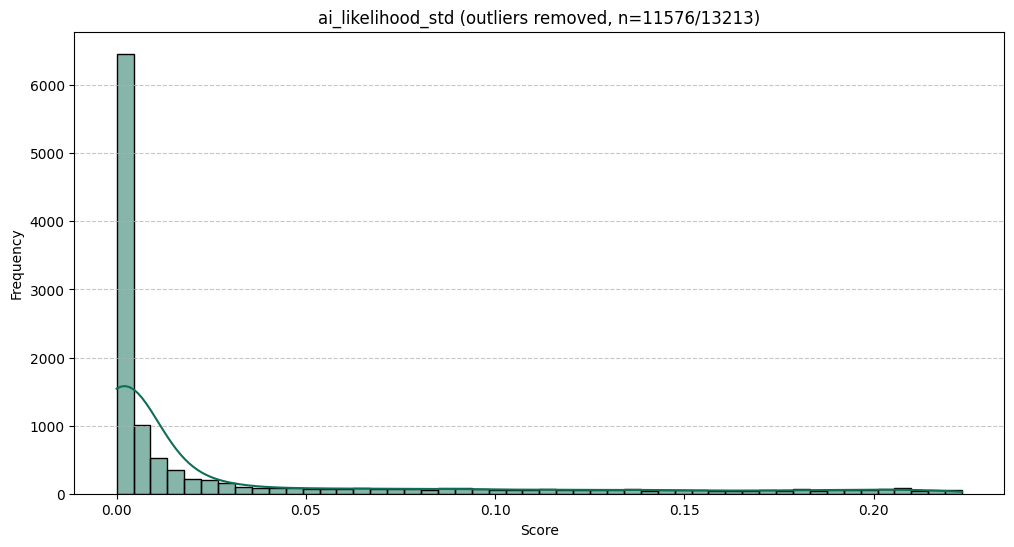

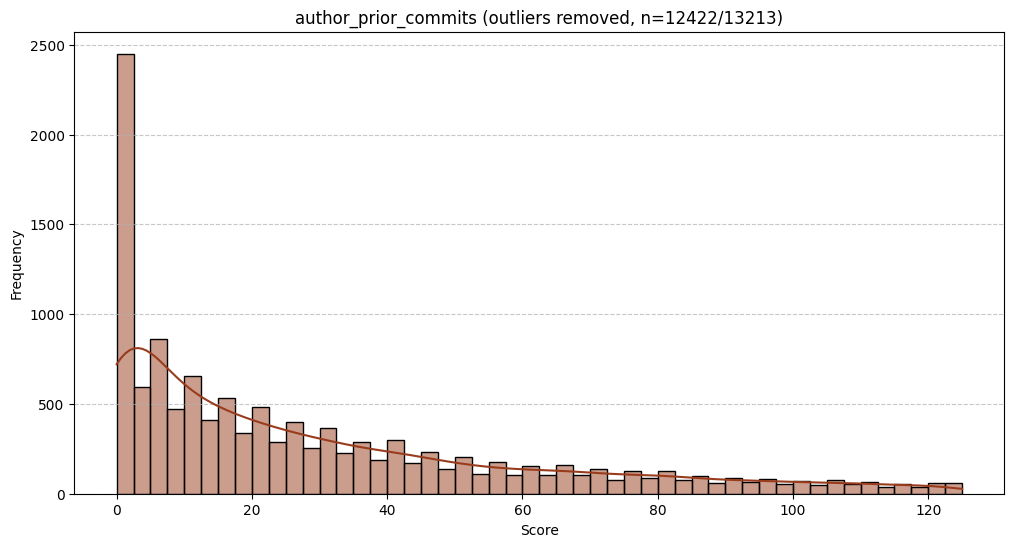

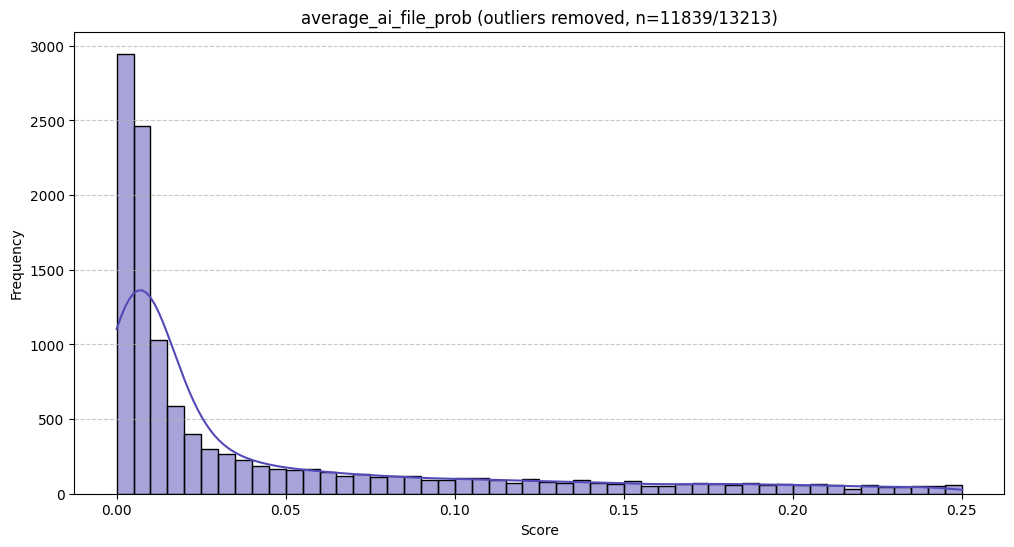

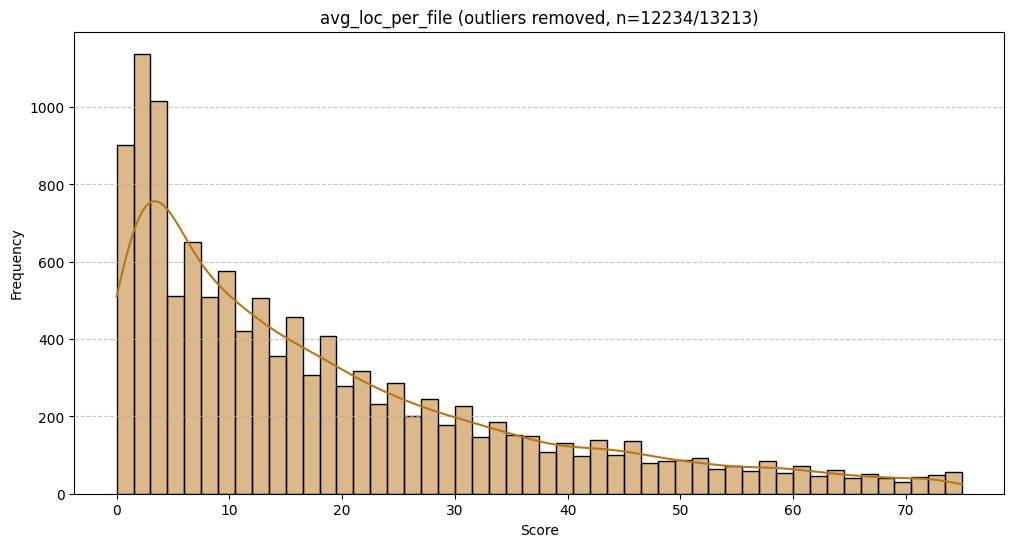

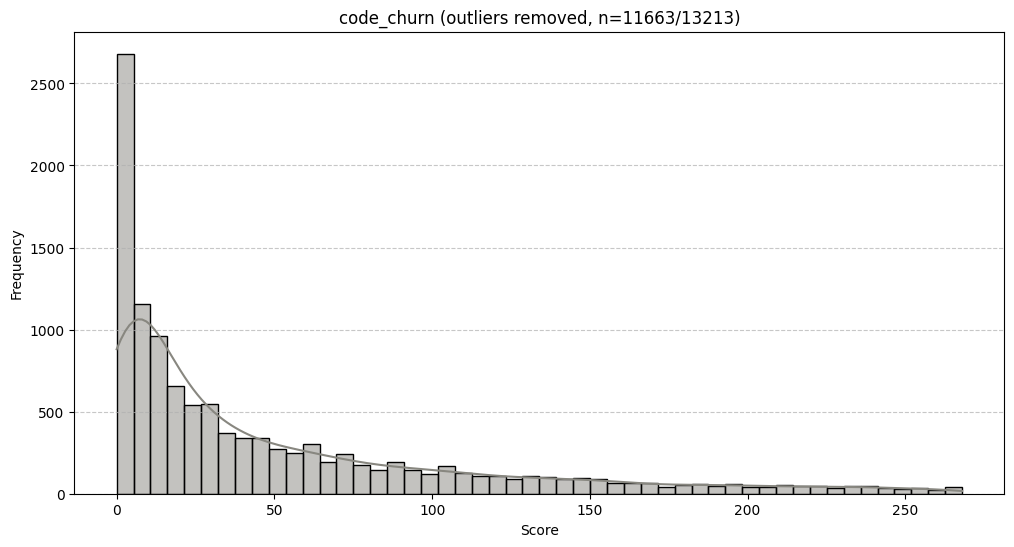

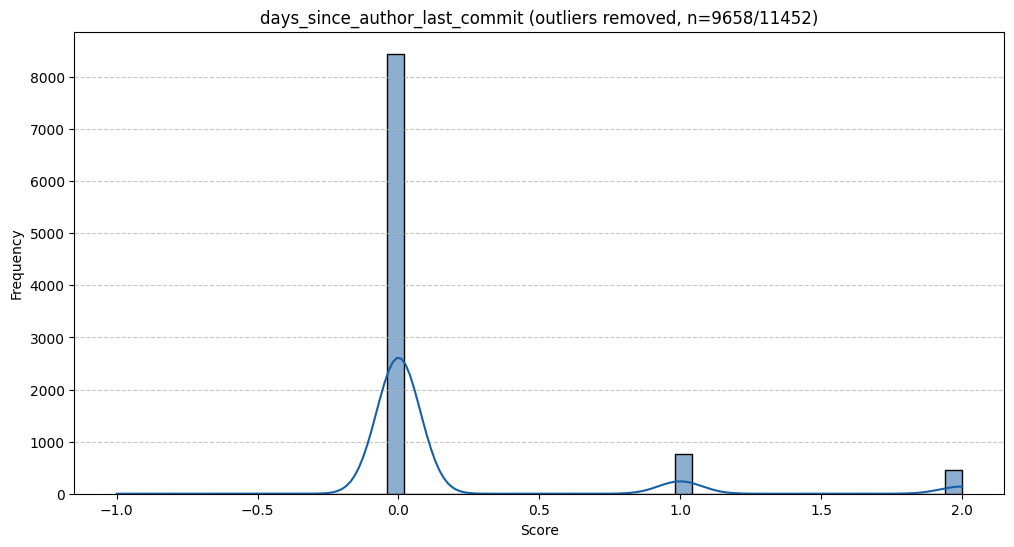

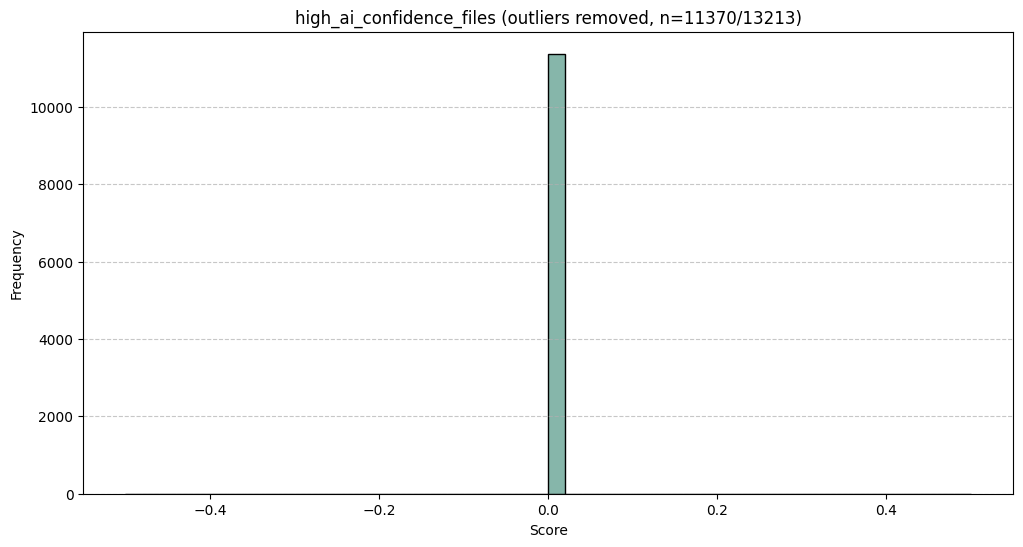

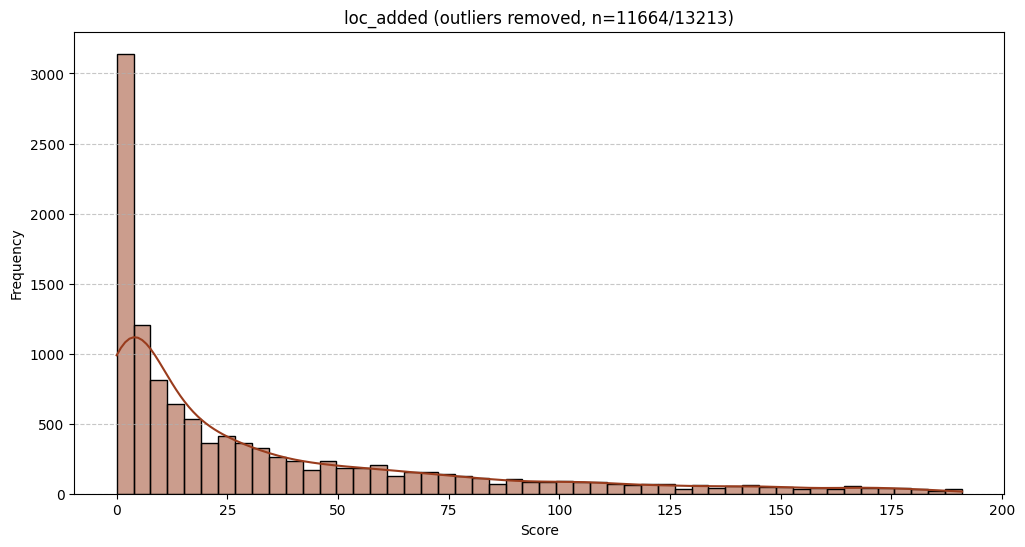

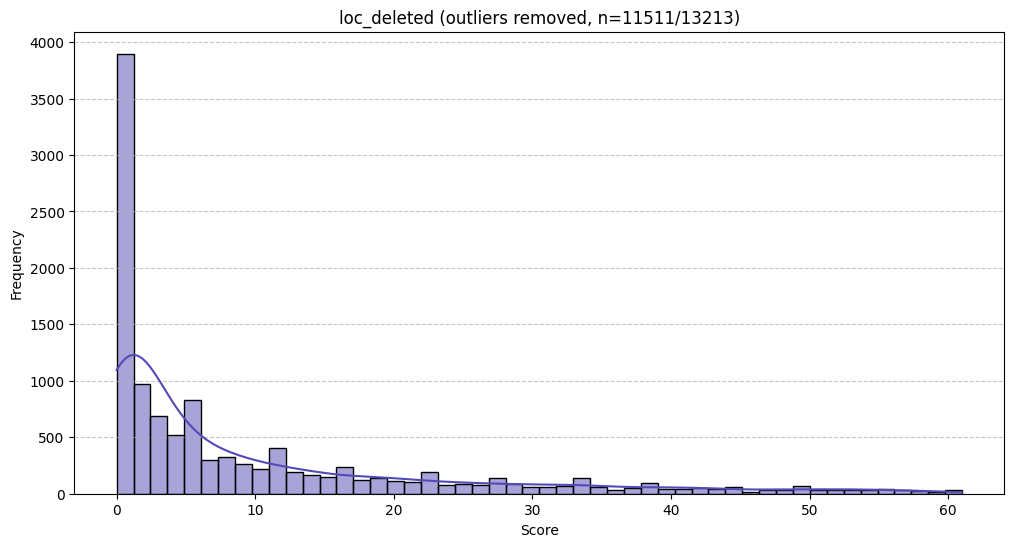

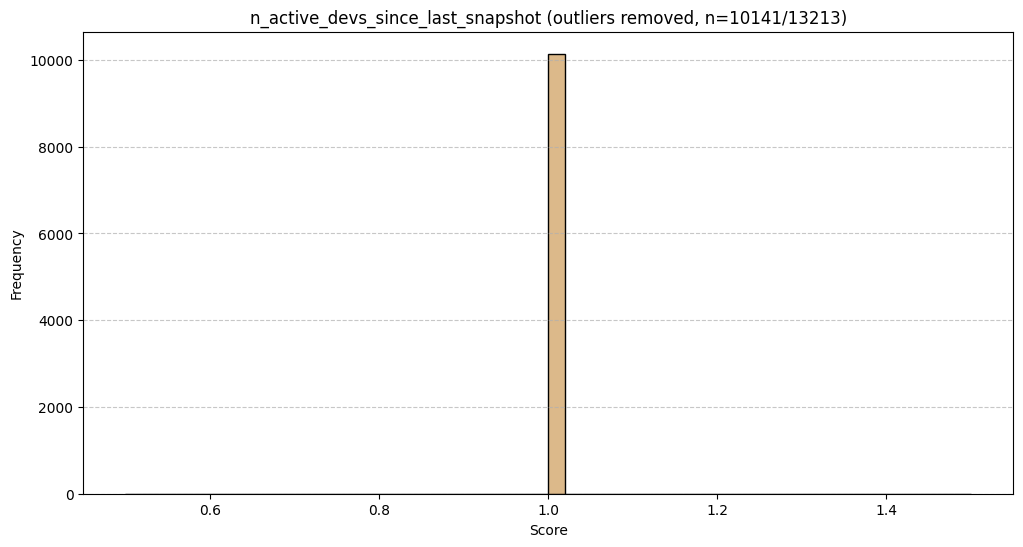

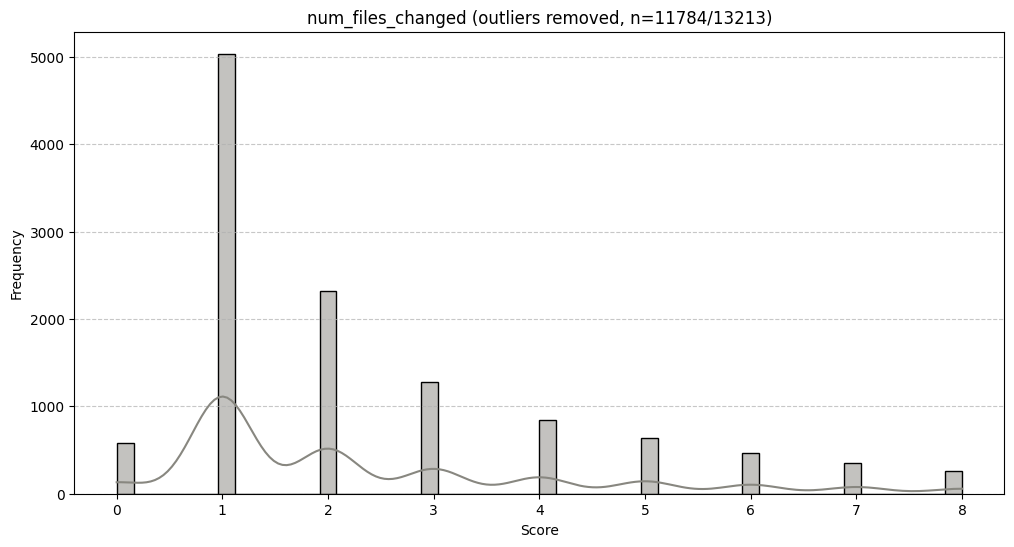

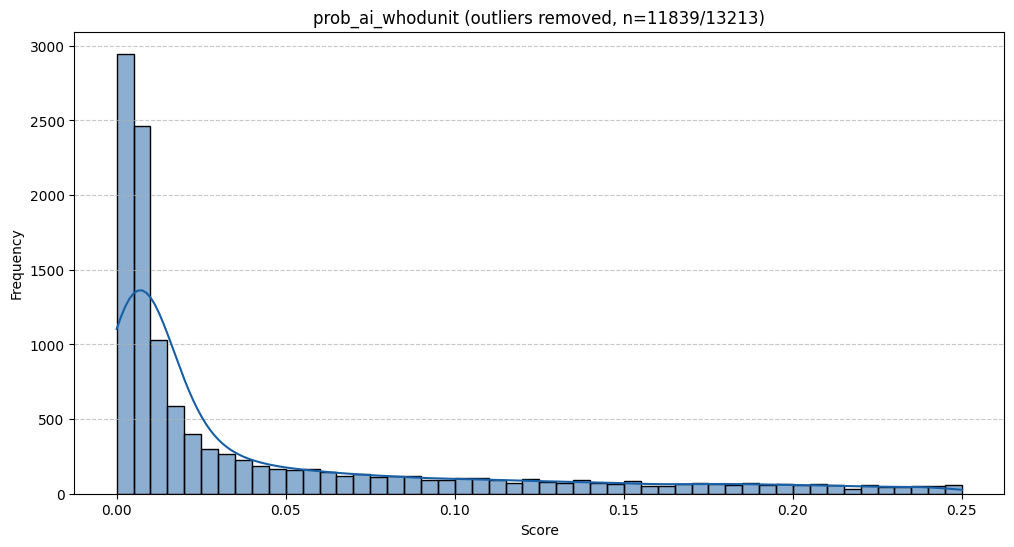

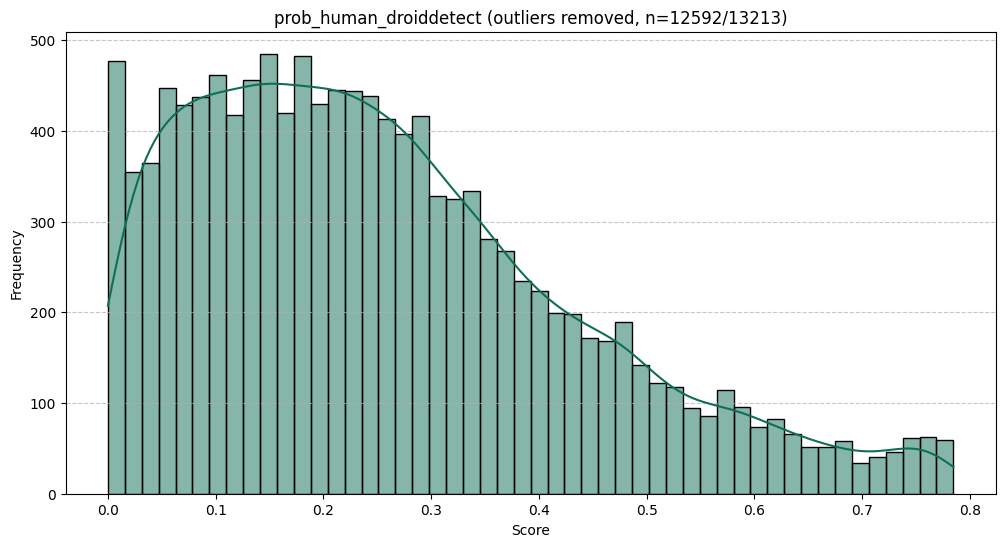

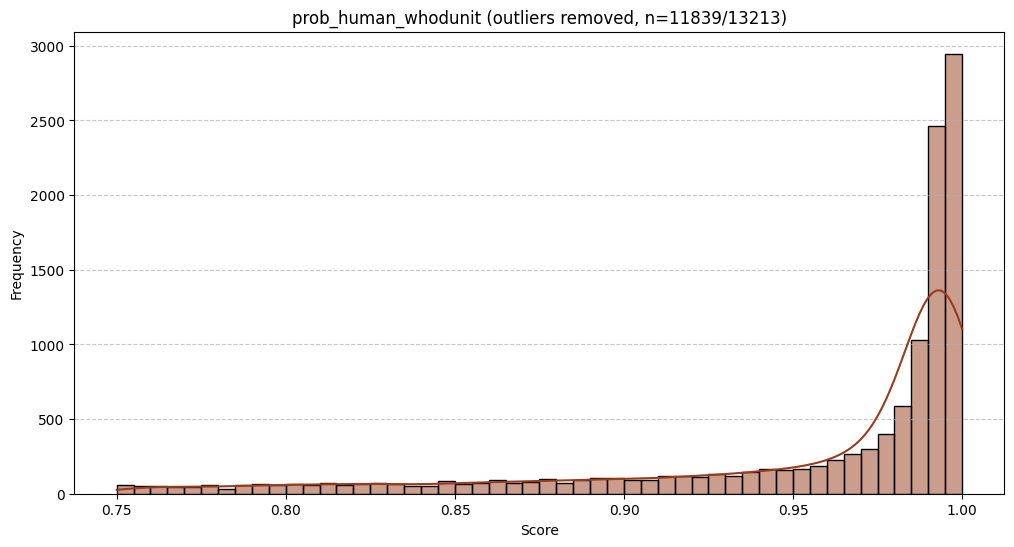

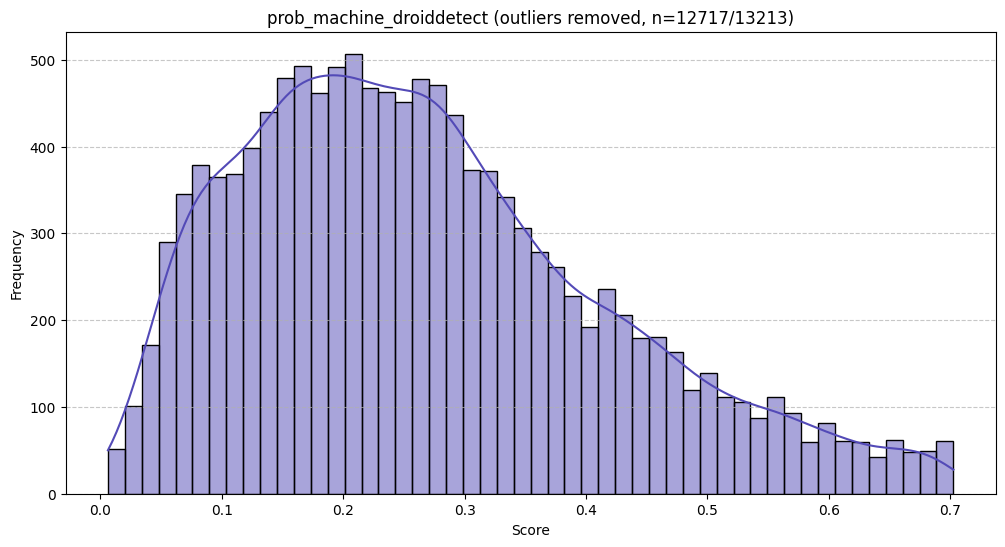

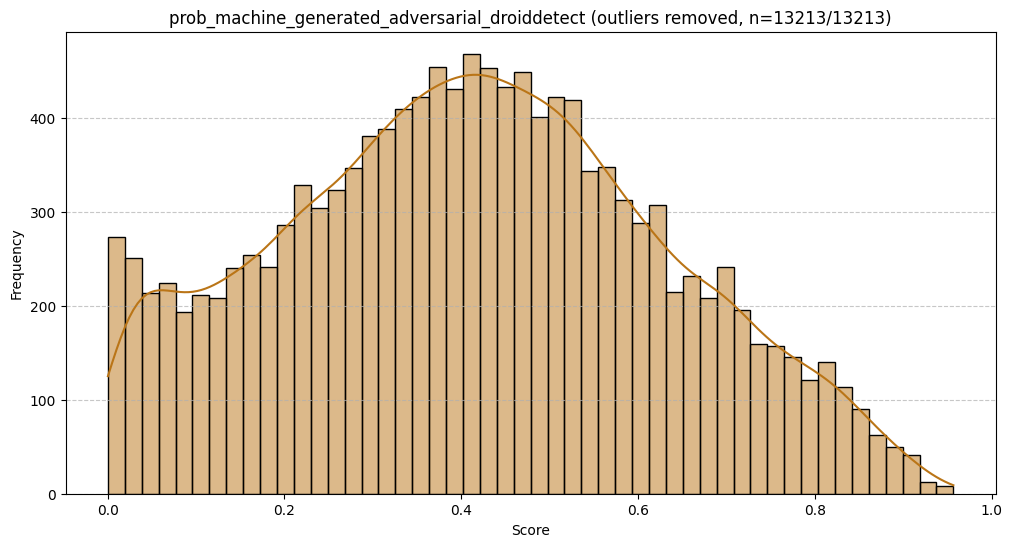

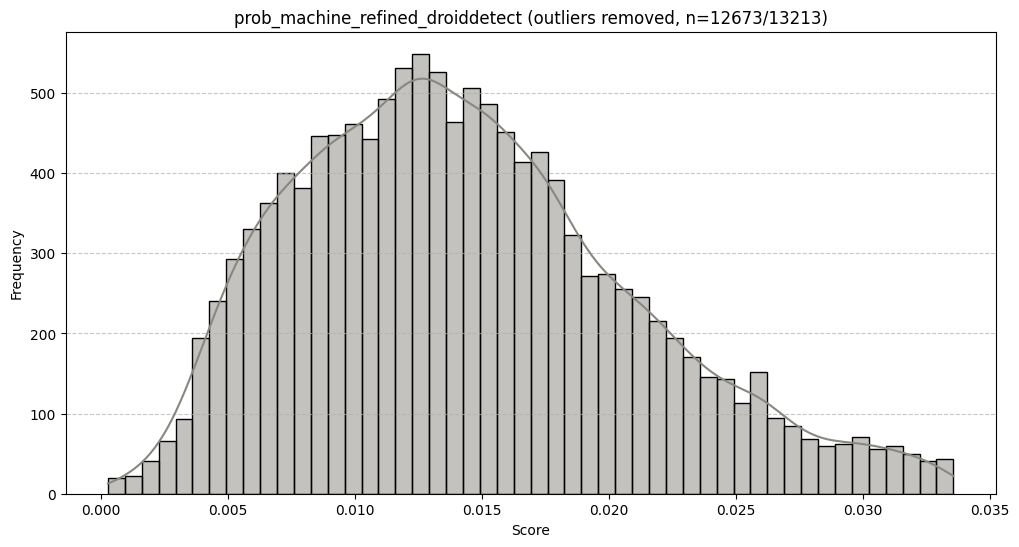

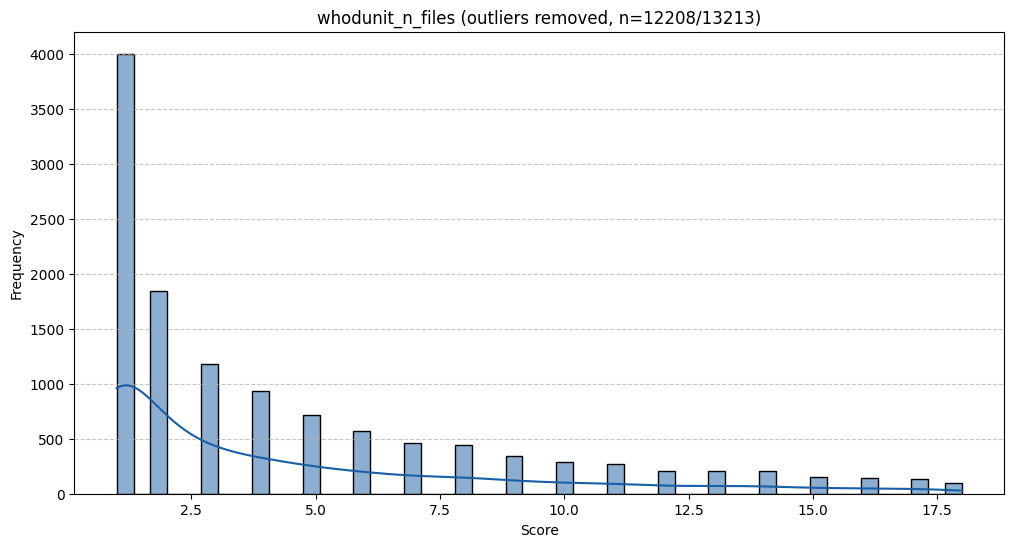

In [15]:
from scipy import stats

columns_to_plot = aiup_df.columns.difference(["repository_id", "author_id", "commit_date_str", "snapshot_commit", "date", "project_year", "languages"])

print("AI Usage Profile columns to plot:", columns_to_plot)
for i, col in enumerate(columns_to_plot):
    data = aiup_df[col].dropna()
    
    # Remove outliers using IQR
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR = Q3 - Q1
    filtered = data[(data >= Q1 - 1.5 * IQR) & (data <= Q3 + 1.5 * IQR)]
    
    plt.figure(figsize=(12, 6))
    sns.histplot(filtered, bins=50, kde=True, color=BUCKET_COLORS[i % len(BUCKET_COLORS)])
    # Add a distribution line over
    
    plt.title(f'{col} (outliers removed, n={len(filtered)}/{len(data)})')
    plt.xlabel('Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.savefig(f'aiup/figure_{col}_distribution.png')
    plt.show()

AI Usage Profile EOP columns to plot: Index(['prob_ai_whodunit', 'prob_human_droiddetect', 'prob_human_whodunit',
       'prob_machine_droiddetect',
       'prob_machine_generated_adversarial_droiddetect',
       'prob_machine_refined_droiddetect'],
      dtype='str')


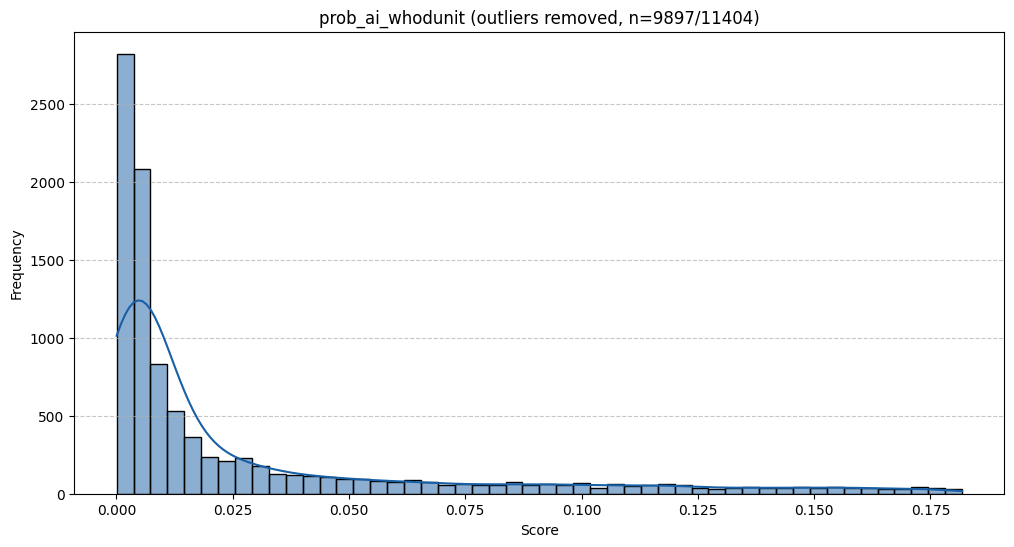

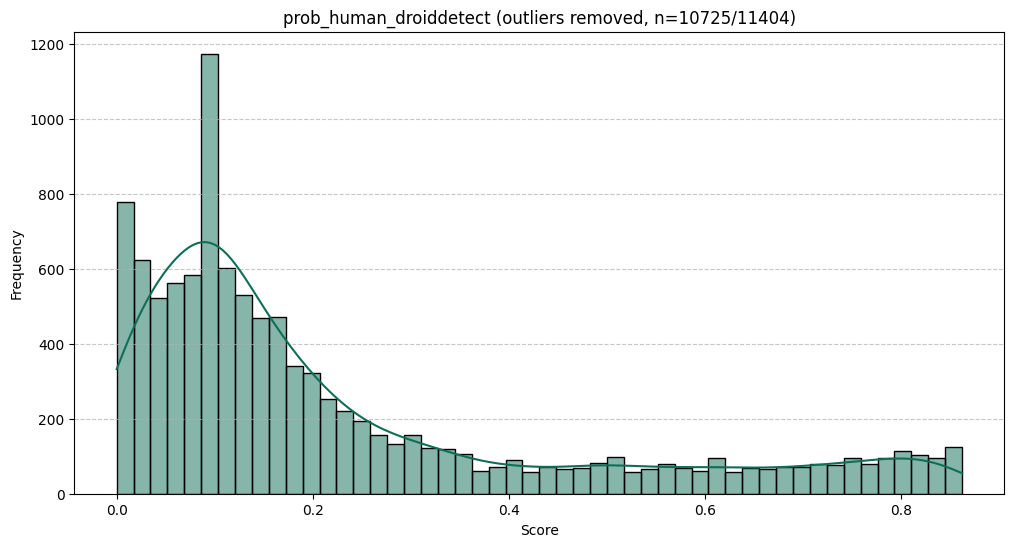

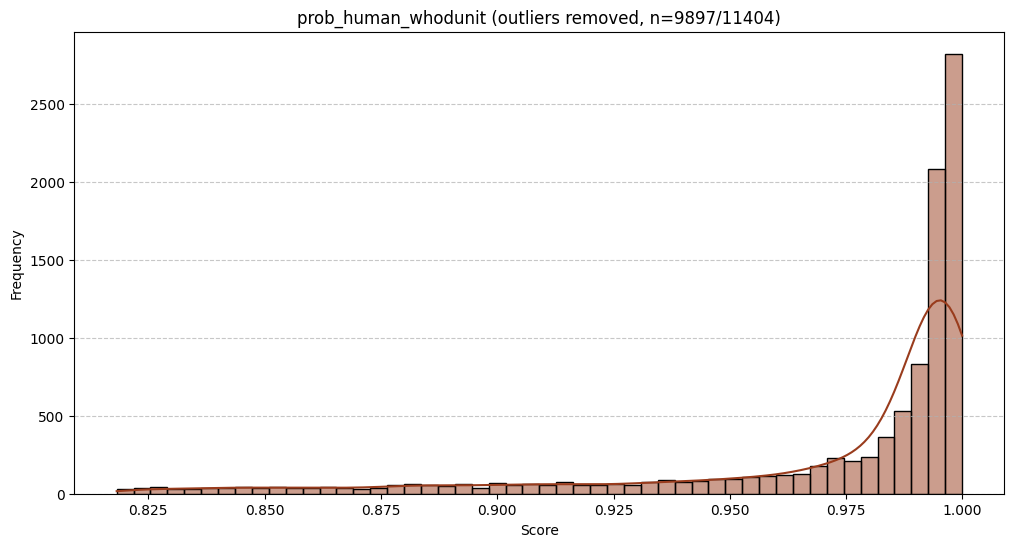

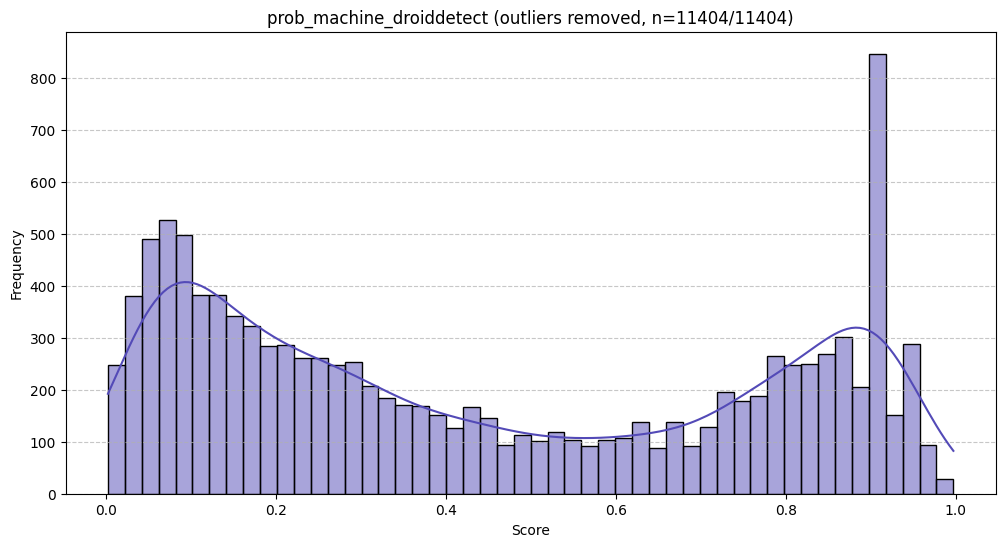

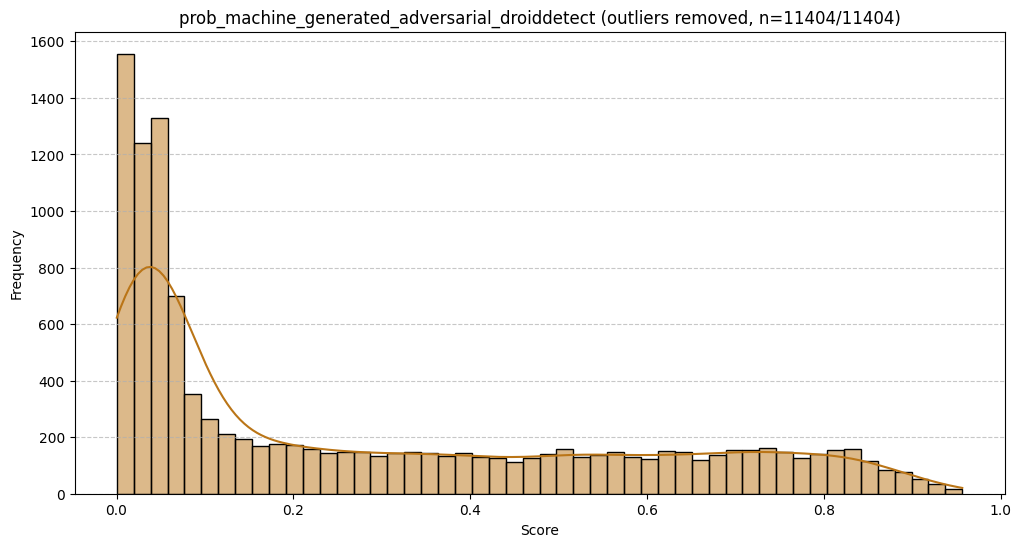

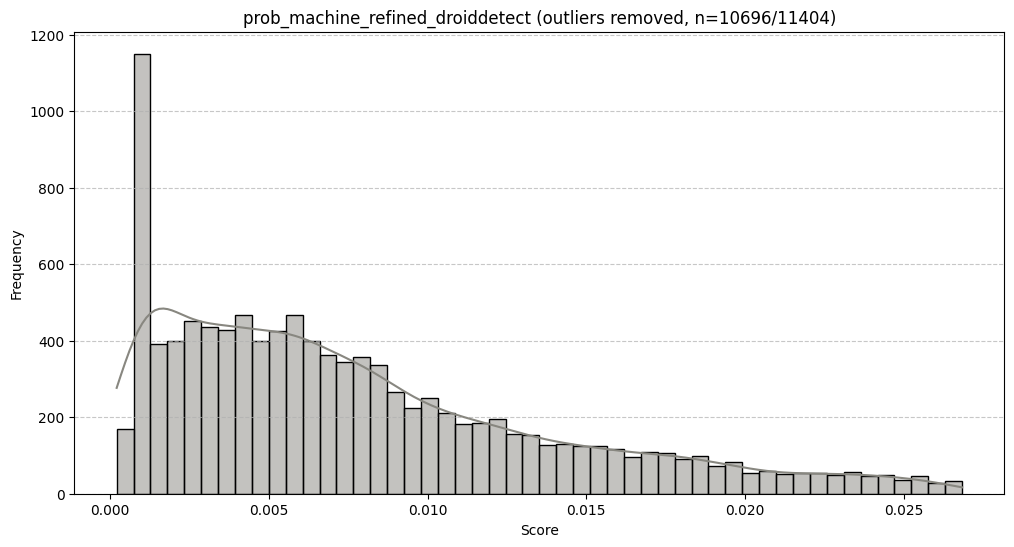

In [16]:
from scipy import stats

columns_to_plot = aiup_eop_df.columns.difference(["repository_id", "filepath", "commit_date_str", "snapshot_commit", "date", "project_year", "languages"])

print("AI Usage Profile EOP columns to plot:", columns_to_plot)
for i, col in enumerate(columns_to_plot):
    data = aiup_eop_df[col].dropna()
    
    # Remove outliers using IQR
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR = Q3 - Q1
    filtered = data[(data >= Q1 - 1.5 * IQR) & (data <= Q3 + 1.5 * IQR)]
    
    plt.figure(figsize=(12, 6))
    sns.histplot(filtered, bins=50, kde=True, color=BUCKET_COLORS[i % len(BUCKET_COLORS)])
    # Add a distribution line over
    
    plt.title(f'{col} (outliers removed, n={len(filtered)}/{len(data)})')
    plt.xlabel('Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.savefig(f'aiup_eop/figure_{col}_distribution.png')
    plt.show()

AI Component Profile columns to plot: Index(['ai_component_count', 'has_ai_component', 'project_year'], dtype='str')


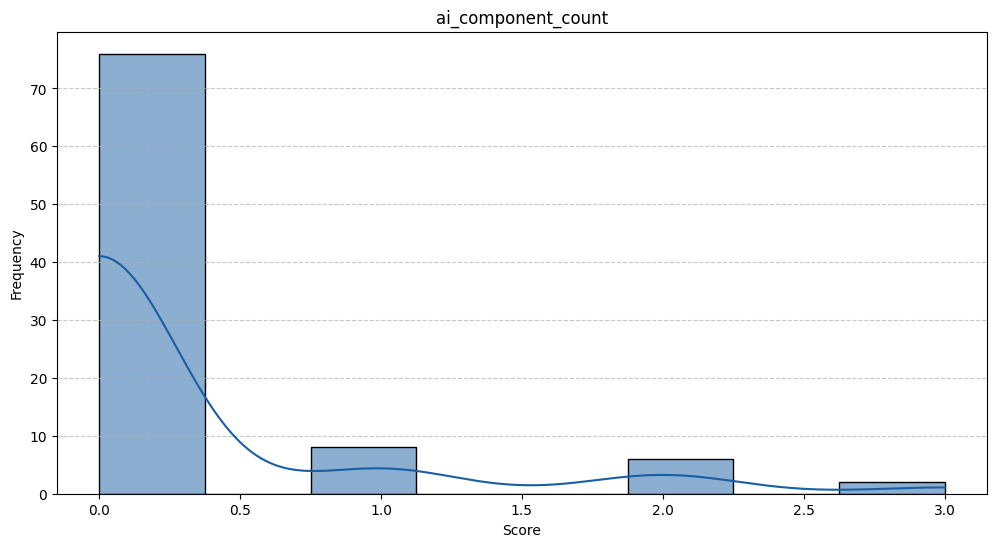

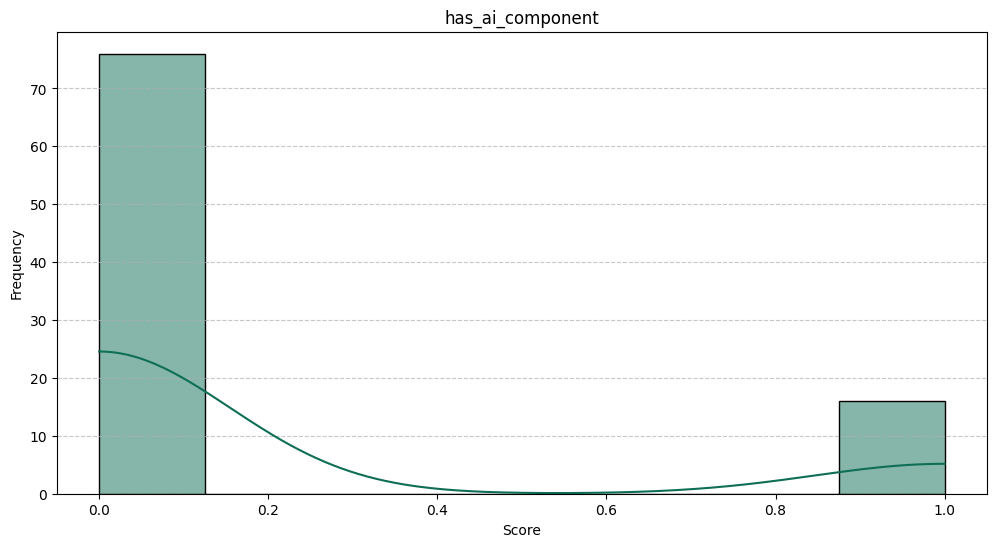

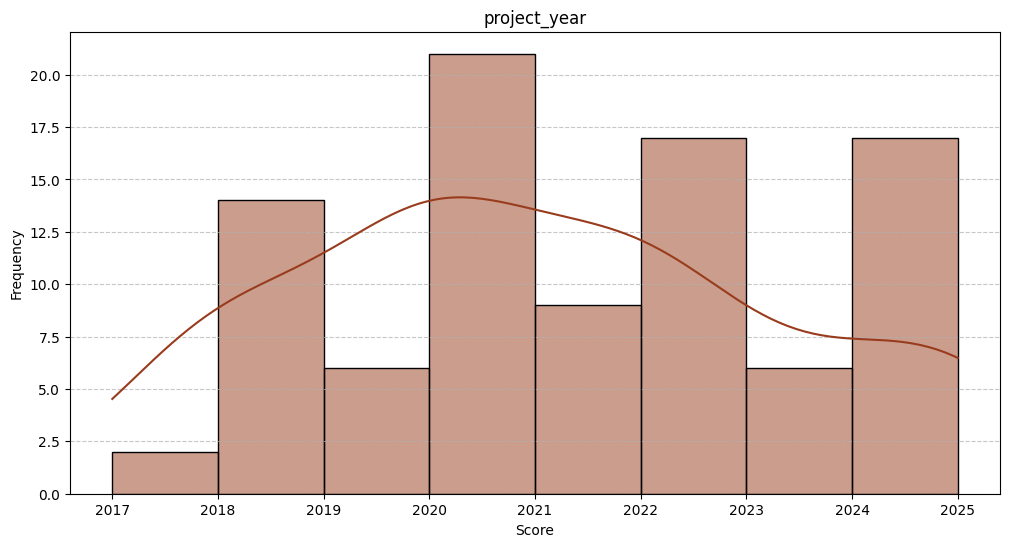

In [17]:
from scipy import stats

columns_to_plot = aicp_df.columns.difference(["repository_id", 'ai_entry_points', 'ai_frameworks',
       'ai_model_type', 'ai_online_inference', 'ai_training_in_repo',
       'is_verified_by_report', 'primary_ai_role',
       'primary_ai_task', 'report_path', 'secondary_ai_task' ])

print("AI Component Profile columns to plot:", columns_to_plot)
for i, col in enumerate(columns_to_plot):
    data = aicp_df[col].dropna()
    
    # Remove outliers using IQR
    plt.figure(figsize=(12, 6))
    sns.histplot(data, bins=8, kde=True, color=BUCKET_COLORS[i % len(BUCKET_COLORS)])
    # Add a distribution line over
    
    plt.title(f'{col}')
    plt.xlabel('Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.savefig(f'aicp/figure_{col}_distribution.png')
    plt.show()

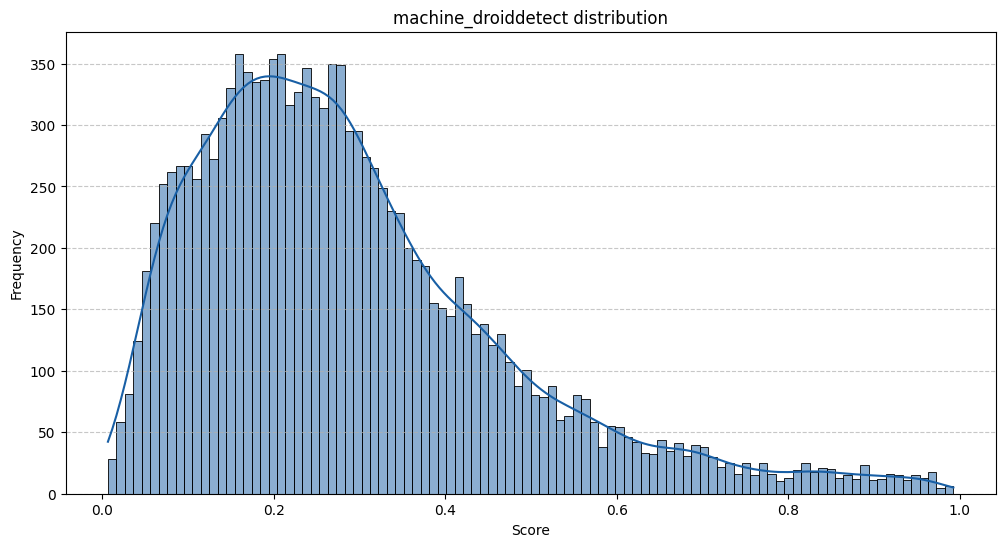

In [18]:
#plot droiddetect from aiup

plt.figure(figsize=(12, 6))
sns.histplot(aiup_df["prob_machine_droiddetect"], bins=100, kde=True, color=BUCKET_COLORS[0])
plt.title('machine_droiddetect distribution')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [19]:
# Plot projects with ai components per year

aicp_only_with_ai = aicp_df[aicp_df['has_ai_component'] == True]
aicp_no_ai = aicp_df[aicp_df['has_ai_component'] == False]

projects_with_ai_per_year= aicp_only_with_ai.groupby('project_year')['repository_id'].nunique()

total_projects        = aicp_df['repository_id'].nunique()
projects_with_ai      = aicp_only_with_ai['repository_id'].nunique()
projects_without_ai   = aicp_no_ai['repository_id'].nunique()
pct_with_ai           = projects_with_ai / total_projects * 100

ai_component_counts   = aicp_only_with_ai.groupby('repository_id')['ai_component_count'].max()

print("=" * 50)
print("AI Component Profile — Descriptive Statistics")
print("=" * 50)
print(f"Total projects:                  {total_projects}")
print(f"Projects with AI component:      {projects_with_ai} ({pct_with_ai:.1f}%)")
print(f"Projects without AI component:   {projects_without_ai} ({100 - pct_with_ai:.1f}%)")
print()
print("AI component count (projects with AI only):")
print(f"  Mean:    {ai_component_counts.mean():.2f}")
print(f"  Median:  {ai_component_counts.median():.2f}")
print(f"  Std:     {ai_component_counts.std():.2f}")
print(f"  Min:     {ai_component_counts.min():.0f}")
print(f"  Max:     {ai_component_counts.max():.0f}")
print()
print("Projects with AI components per year:")
print(projects_with_ai_per_year.to_string())
print()
print("Projects without AI components per year:")
print(aicp_no_ai.groupby('project_year')['repository_id'].nunique().to_string())
print()
print("AI component count distribution:")
print(ai_component_counts.value_counts().sort_index().to_string())

AI Component Profile — Descriptive Statistics
Total projects:                  92
Projects with AI component:      16 (17.4%)
Projects without AI component:   76 (82.6%)

AI component count (projects with AI only):
  Mean:    1.62
  Median:  1.50
  Std:     0.72
  Min:     1
  Max:     3

Projects with AI components per year:
project_year
2019    2
2020    2
2021    1
2022    3
2023    2
2024    3
2025    3

Projects without AI components per year:
project_year
2017     2
2018    14
2019     4
2020    19
2021     8
2022    14
2023     4
2024     3
2025     8

AI component count distribution:
ai_component_count
1    8
2    6
3    2


In [20]:
# ── Universal colour palette ──────────────────────────────────────────────────
# All colours tested for mutual harmony and sufficient contrast on white/light bg

# Group / category colours
C_AI        = "#2563EB"   # blue        – AI-product group
C_DEV       = "#575B64"   # slate grey  – no AI-product group
C_ORANGE    = "#EA6C00"   # orange      – third category / accent
C_GREEN     = "#0F8C4A"   # green       – fourth category
C_RED       = "#CC1F1F"   # red         – fifth category
C_PURPLE    = "#6D28D9"   # violet      – sixth category
C_TEAL      = "#0891B2"   # teal        – seventh category

# A ready-made ordered list for cycling through groups
CATEGORY_COLORS = [C_AI, C_ORANGE, C_GREEN, C_RED, C_PURPLE, C_TEAL, C_DEV]

# Significance / annotation colours
C_SIG       = "#0F8C4A"   # green  – statistically significant  (matches C_GREEN)
C_TREND     = "#EA6C00"   # amber  – trending                   (matches C_ORANGE)
C_NS        = "#BFC8D7"   # light grey – not significant

# Direction colours (right-panel bars)
C_POS       = "#2563EB"   # blue – AI group higher              (matches C_AI)
C_NEG       = "#CC1F1F"   # red  – no-AI group higher           (matches C_RED)

# Text colours
C_TEXT      = "#111827"   # near-black – significant rows / primary labels
C_TEXT_NS   = "#6B7280"   # mid grey   – non-significant rows
C_TEXT_SOFT = "#9CA3AF"   # light grey – annotations / secondary labels

# Row / background shading
C_ROW_SIG   = "#F0FDF4"   # very light green – significant row highlight
C_ROW_TREND = "#FFF7ED"   # very light amber – trending row highlight
C_ROW_ALT   = "#F9FAFB"   # off-white        – alternating row stripe
C_ROW       = "#FFFFFF"   # white            – default row
C_ROW_SHADING = "#F9FAFB"  # light grey for alternating row shading

# Hatch patterns paired with CATEGORY_COLORS for B&W printing
CATEGORY_HATCHES = ["", "///", "...", "xxx", "\\\\\\", "+++", "|||"]

In [21]:
data = [
    # (year, has_ai, model_category)
    (2017, False, None), (2017, False, None),
    *[(2018, False, None)] * 14,
    (2019, False, None), (2019, False, None), (2019, False, None), (2019, False, None),
    (2019, True, "CNN / Computer vision"),
    (2019, True, "CNN / Computer vision"),
    *[(2020, False, None)] * 19,
    (2020, True, "Classical ML"),
    (2020, True, "Classical ML"),
    *[(2021, False, None)] * 8,
    (2021, True, "Transformer NLP (pre-LLM)"),
    *[(2022, False, None)] * 14,
    (2022, True, "CNN / Computer vision"),
    (2022, True, "CNN / Computer vision"),
    (2022, True, "Time-series forecasting"),
    *[(2023, False, None)] * 4,
    (2023, True, "LLM / RAG / GenAI"),
    (2023, True, "Classical ML"),
    *[(2024, False, None)] * 3,
    (2024, True, "LLM / RAG / GenAI"),
    (2024, True, "LLM / RAG / GenAI"),
    (2024, True, "LLM / RAG / GenAI"),
    *[(2025, False, None)] * 8,
    (2025, True, "LLM / RAG / GenAI"),
    (2025, True, "LLM / RAG / GenAI"),
    (2025, True, "LLM / RAG / GenAI"),
]
df_prima = pd.DataFrame(data, columns=["project_year", "has_ai_component", "model_category"])
 

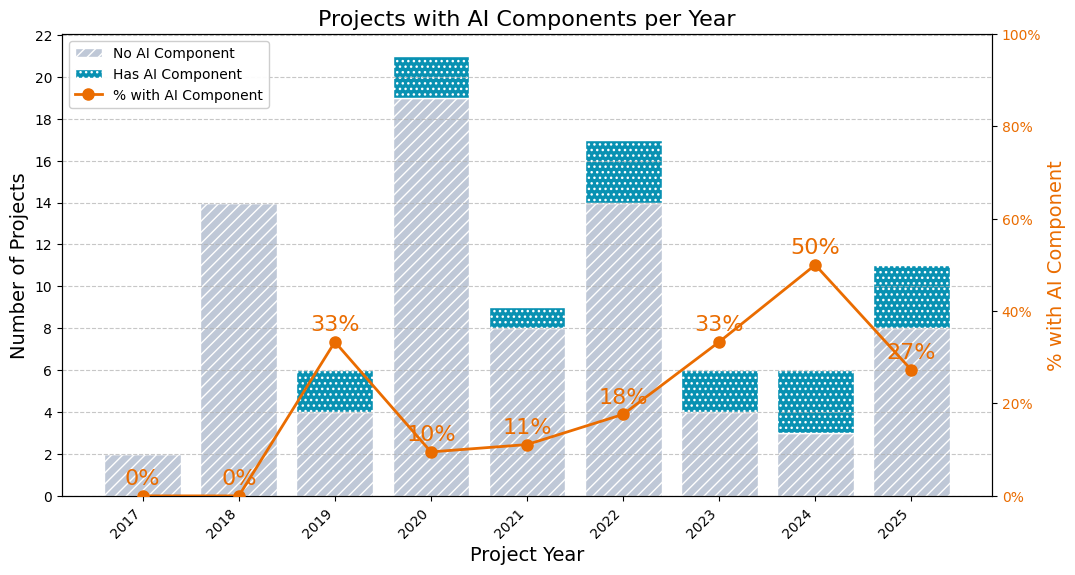

In [22]:
pivot = (df_prima.groupby(["project_year", "has_ai_component"])
         .size()
         .reset_index(name="count")
         .pivot(index="project_year", columns="has_ai_component", values="count")
         .fillna(0))
 
fig, ax = plt.subplots(figsize=(12, 6))
 
bars_no = ax.bar(pivot.index, pivot[False], color=C_NS, hatch=CATEGORY_HATCHES[1],
                 label="No AI Component", edgecolor="white")
bars_ai = ax.bar(pivot.index, pivot[True], bottom=pivot[False], color=C_TEAL,
                 hatch=CATEGORY_HATCHES[2], label="Has AI Component", edgecolor="white")
 
ax.set_title("Projects with AI Components per Year", fontsize=16)
ax.set_xlabel("Project Year", fontsize=14)
ax.set_ylabel("Number of Projects", fontsize=14)
ax.set_xticks(pivot.index)
ax.set_xticklabels(pivot.index, rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.7)
ax.yaxis.set_major_locator(plt.MultipleLocator(2))
 
# Trendline on twin axis — keep the axis reference so it's not discarded
ax2 = ax.twinx()
pct = pivot[True] / (pivot[True] + pivot[False]) * 100
line, = ax2.plot(pivot.index, pct, color=C_ORANGE, marker="o", linewidth=2,
                 markersize=8, label="% with AI Component", zorder=5)
ax2.set_ylabel("% with AI Component", fontsize=14, color=C_ORANGE)
ax2.tick_params(axis="y", labelcolor=C_ORANGE)
ax2.set_ylim(0, 100)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v)}%"))
 
# Annotate trendline points with percentages
for x, y in zip(pivot.index, pct):
    ax2.annotate(f"{y:.0f}%", xy=(x, y), xytext=(0, 8),
                 textcoords="offset points", ha="center", fontsize=16, color=C_ORANGE)
 
# Combined legend (bars from ax + line from ax2)
handles = [bars_no, bars_ai, line]
labels = [h.get_label() for h in handles]
ax.legend(handles, labels, loc="upper left", framealpha=0.95)

plt.savefig("overleaf/AICP_Component_per_year.pdf", format="pdf")

In [23]:
ai_df = df_prima[df_prima["has_ai_component"]].copy()
 
category_order = [
    "CNN / Computer vision",
    "Classical ML",
    "Transformer NLP (pre-LLM)",
    "Time-series forecasting",
    "LLM / RAG / GenAI",
]

category_colors = {
    "CNN / Computer vision":      C_DEV,
    "Classical ML":               C_AI,
    "Transformer NLP (pre-LLM)":  C_PURPLE,
    "Time-series forecasting":    C_ORANGE,
    "LLM / RAG / GenAI":          C_GREEN,
}

#  C_AI        = "#2563EB"   # blue        – AI-product group
# C_DEV       = "#575B64"   # slate grey  – no AI-product group
# C_ORANGE    = "#EA6C00"   # orange      – third category / accent
# C_GREEN     = "#0F8C4A"   # green       – fourth category
# C_RED       = "#CC1F1F"   # red         – fifth category
# C_PURPLE    = "#6D28D9"   # violet      – sixth category
# C_TEAL      = "#0891B2"   # teal        – seventh category


model_pivot = (ai_df.groupby(["project_year", "model_category"])
               .size()
               .unstack(fill_value=0)
               .reindex(columns=category_order, fill_value=0))
 
# Ensure all years are shown (even those with zero AI repos)
all_years = sorted(df["project_year"].unique())
model_pivot = model_pivot.reindex(all_years, fill_value=0)
 
fig, ax = plt.subplots(figsize=(12, 6))
 
bottom = pd.Series([0] * len(model_pivot), index=model_pivot.index, dtype=float)
for i, cat in enumerate(category_order):
    values = model_pivot[cat]
    ax.bar(model_pivot.index, values, bottom=bottom,
           color=category_colors[cat],
           hatch=CATEGORY_HATCHES[i % len(CATEGORY_HATCHES) + 1],
           label=cat, edgecolor="white")
    bottom = bottom + values
 
ax.set_title("Dominant AI Model Family per Year", fontsize=16)
ax.set_xlabel("Project Year", fontsize=14)
ax.set_ylabel("Number of AI Repositories", fontsize=14)
ax.set_xticks(model_pivot.index)
ax.set_xticklabels(model_pivot.index, rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.7)
ax.yaxis.set_major_locator(plt.MultipleLocator(1))
ax.set_ylim(0, model_pivot.sum(axis=1).max() + 1)
ax.tick_params(axis="y", labelsize=12)

ax.legend(title="Model family", loc="upper left", framealpha=0.95)

plt.savefig("overleaf/AICP_model_family_per_year.pdf", format="pdf")

NameError: name 'df' is not defined

In [ ]:
# Make the associated df
display(pivot)

has_ai_component,False,True
project_year,,
2017,2.0,0.0
2018,14.0,0.0
2019,4.0,2.0
2020,19.0,2.0
2021,8.0,1.0
2022,14.0,3.0
2023,4.0,2.0
2024,3.0,3.0
2025,8.0,3.0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from collections import defaultdict
 

df = aicp_df.copy()
ai = df[df["has_ai_component"] == True].copy()

def split_frameworks(s):
    """Split a free-text ai_frameworks string into individual tech entries."""
    if pd.isna(s) or s == "None":
        return []
    # Drop mentions of generic "compatible ecosystem" / "ecosystem" — these
    # describe interop, not actual frameworks the project uses.
    s = re.sub(r"[^,]*ecosystem[^,]*", "", s, flags=re.IGNORECASE)
    # Pull out specific OCR libraries that appear inside parentheses
    # e.g. "OCR libraries (easyocr, pytesseract)"
    inner = re.findall(r"\(([^)]*easyocr[^)]*)\)", s, flags=re.IGNORECASE)
    extras = []
    for inside in inner:
        extras.extend([x.strip() for x in inside.split(",")])
    # Remove the now-redundant "OCR libraries (...)" wrapper
    s = re.sub(r"OCR libraries\s*\([^)]*\)", "", s, flags=re.IGNORECASE)
    parts = re.split(r",\s*(?![^()]*\))", s)
    cleaned = [p.strip().rstrip(".") for p in parts if p.strip()]
    return cleaned + extras
 
ai["frameworks_list"] = ai["ai_frameworks"].apply(split_frameworks)
 
# Explode into one row per (repo, framework)
exploded = ai.explode("frameworks_list").rename(columns={"frameworks_list": "raw_framework"})
exploded = exploded[exploded["raw_framework"].notna()]
 
# -------------------------------------------------------------------
# Normalize raw framework names → canonical names
# (handles spelling variants like "Langchain" vs "LangChain")
# -------------------------------------------------------------------
def normalize(raw):
    r = raw.lower()
    # Order matters — match more specific patterns first
    if "langchain" in r:                              return ("LangChain",                 "RAG / orchestration")
    if "google genai" in r or "gemini api" in r:      return ("Google GenAI SDK",          "RAG / orchestration")
    if "openai embed" in r:                           return ("OpenAI Embeddings API",     "Vector / embedding store")
    if "openai" in r:                                 return ("OpenAI API",                "LLM API")
    if "azure openai" in r:                           return ("Azure OpenAI",              "LLM API")
    if "gemini" in r:                                 return ("Google Gemini",             "LLM API")
    if "llama" in r:                                  return ("Llama 3.1",                 "LLM API")
    if "idun" in r:                                   return ("IDUN (NTNU HPC)",           "LLM API")
    if "weaviate" in r:                               return ("Weaviate",                  "Vector / embedding store")
    if "supabase" in r:                               return ("Supabase (pgvector)",       "Vector / embedding store")
    if "whisper" in r:                                return ("Whisper",                   "Speech / audio")
    if "onnx" in r:                                   return ("ONNX",                      "Speech / audio")
    if "librosa" in r:                                return ("Librosa",                   "Speech / audio")
    if "tesseract" in r and "py" not in r:            return ("Tesseract OCR",             "OCR")
    if "pytesseract" in r:                            return ("pytesseract",               "OCR")
    if "easyocr" in r:                                return ("easyocr",                   "OCR")
    if "ocr librar" in r:                             return ("OCR libraries",             "OCR")
    if "opencv" in r:                                 return ("OpenCV",                    "OCR")
    if "darts" in r:                                  return ("Darts",                     "Time-series forecasting")
    if "prophet" in r:                                return ("Prophet",                   "Time-series forecasting")
    if "xgboost" in r:                                return ("XGBoost",                   "Classical ML")
    if "scikit" in r:                                 return ("scikit-learn",              "Classical ML")
    if "tensorflow" in r and "keras" in r:            return ("TensorFlow / Keras",        "Deep learning framework")
    if "tensorflow" in r:                             return ("TensorFlow",                "Deep learning framework")
    if "keras" in r:                                  return ("Keras",                     "Deep learning framework")
    if "pytorch" in r:                                return ("PyTorch",                   "Deep learning framework")
    if "torchvision" in r:                            return ("torchvision",               "Deep learning framework")
    if "yolov3" in r or "yolo" in r:                  return ("YOLOv3",                    "Pretrained model (CV)")
    if "resnet" in r:                                 return ("ResNet",                    "Pretrained model (CV)")
    if "efficientnet" in r:                           return ("EfficientNet",              "Pretrained model (CV)")
    if "distilbert" in r:                             return ("DistilBERT",                "NLP library (pre-LLM)")
    if "huggingface" in r or "transformers" in r:     return ("HuggingFace transformers",  "NLP library (pre-LLM)")
    if "rasa" in r:                                   return ("Rasa",                      "NLP library (pre-LLM)")
    if "spacy" in r:                                  return ("SpaCy",                     "NLP library (pre-LLM)")
    if "numpy" in r:                                  return ("NumPy",                     "Numerical / data")
    if "pandas" in r:                                 return ("Pandas",                    "Numerical / data")
    if "scipy" in r:                                  return ("SciPy",                     "Numerical / data")
    if "django" in r:                                 return ("Django",                    "Backend / orchestration")
    if "requests" in r:                               return ("requests",                  "Backend / orchestration")
    if raw.lower() in ("math", "custom"):             return ("Custom math",               "Classical ML")
    # Fallback — keep raw, mark uncategorized
    return (raw.strip(), "Other / uncategorized")
 
norm = exploded["raw_framework"].apply(normalize).tolist()
exploded["technology"] = [n[0] for n in norm]
exploded["category"]   = [n[1] for n in norm]
 
# -------------------------------------------------------------------
# Aggregate to one row per technology
# -------------------------------------------------------------------
agg = (
    exploded.groupby(["category", "technology"])
    .agg(
        years_used=("project_year", lambda s: ", ".join(sorted({str(int(y)) for y in s}))),
        repos=("repository_id", "nunique"),
        example_repos=(
            "repository_id",
            lambda s: ", ".join(sorted({r.split("_", 1)[1][:32] for r in s})[:3]),
        ),
    )
    .reset_index()
    .sort_values(["category", "repos", "technology"], ascending=[True, False, True])
)
 
# Print
print(f"Parsed {len(exploded)} (repo, technology) pairs "
      f"from {ai['ai_frameworks'].notna().sum()} AI repos.\n")
print(agg.to_string(index=False))


Parsed 47 (repo, technology) pairs from 16 AI repos.

                category               technology       years_used  repos                                                          example_repos
 Backend / orchestration                   Django             2025      1                                       CDP-group-9_CDP_Trondheim_Kommun
 Backend / orchestration                 requests             2025      1                                       CDP-group-9_CDP_Trondheim_Kommun
            Classical ML             scikit-learn       2020, 2022      2                     SimenHolmestad_TDT4290-Avalanche, erlandbo_TDT4290
            Classical ML              Custom math             2020      1                                       Studentidrettsforbundet_studenti
            Classical ML                  XGBoost             2023      1                                            askiver_TDT4290_group7_2023
 Deep learning framework                  PyTorch             2022      2   

In [ ]:
table_df = agg[["category", "technology", "years_used", "repos"]].copy()

display(table_df)

,category,technology,years_used,repos
0,Backend / orchestration,Django,2025,1
1,Backend / orchestration,requests,2025,1
4,Classical ML,scikit-learn,"2020, 2022",2
2,Classical ML,Custom math,2020,1
3,Classical ML,XGBoost,2023,1
6,Deep learning framework,PyTorch,2022,2
7,Deep learning framework,TensorFlow,"2020, 2022",2
5,Deep learning framework,Keras,2020,1
11,LLM API,OpenAI API,"2023, 2024, 2025",5
8,LLM API,Google Gemini,2025,2


In [ ]:
import pandas as pd

table_df = agg[["category", "technology", "years_used", "repos"]].copy()
pretty = table_df.rename(columns={
    "category": "Category", "technology": "Technology",
    "years_used": "Years used", "repos": "Repos",
})

latex_str = pretty.to_latex(
    index=False,
    column_format="l l l r",
    escape=True,
    caption="AI technologies parsed from the \\texttt{ai\\_frameworks} column.",
    label="tab:ai-tech-breakdown",
    position="H",
)

# Insert \addlinespace between category groups
lines, out, prev_cat, in_body = latex_str.split("\n"), [], None, False
for line in lines:
    if line.strip() == "\\midrule": in_body = True; out.append(line); continue
    if line.strip() == "\\bottomrule": in_body = False; out.append(line); continue
    if in_body and "&" in line:
        cat = line.split("&")[0].strip()
        if prev_cat is not None and cat != prev_cat: out.append("\\addlinespace")
        prev_cat = cat
    out.append(line)
print("\n".join(out))

\begin{table}[H]
\caption{AI technologies parsed from the \texttt{ai\_frameworks} column.}
\label{tab:ai-tech-breakdown}
\begin{tabular}{l l l r}
\toprule
Category & Technology & Years used & Repos \\
\midrule
Backend / orchestration & Django & 2025 & 1 \\
Backend / orchestration & requests & 2025 & 1 \\
\addlinespace
Classical ML & scikit-learn & 2020, 2022 & 2 \\
Classical ML & Custom math & 2020 & 1 \\
Classical ML & XGBoost & 2023 & 1 \\
\addlinespace
Deep learning framework & PyTorch & 2022 & 2 \\
Deep learning framework & TensorFlow & 2020, 2022 & 2 \\
Deep learning framework & Keras & 2020 & 1 \\
\addlinespace
LLM API & OpenAI API & 2023, 2024, 2025 & 5 \\
LLM API & Google Gemini & 2025 & 2 \\
LLM API & IDUN (NTNU HPC) & 2025 & 1 \\
LLM API & Llama 3.1 & 2024 & 1 \\
\addlinespace
NLP library (pre-LLM) & DistilBERT & 2021 & 1 \\
NLP library (pre-LLM) & HuggingFace transformers & 2021 & 1 \\
NLP library (pre-LLM) & Rasa & 2021 & 1 \\
NLP library (pre-LLM) & SpaCy & 2021 & 1 \\
\ad

In [ ]:
BASE_DIR_2 = Path().resolve().parent.parent / "input_files"
github_links_csv_path = BASE_DIR_2 / "github_links.csv"
github_links_df = pd.read_csv(github_links_csv_path)

display(github_links_df.head())

# dictionary of participants per year
participants_per_year = (
    github_links_df.drop_duplicates(subset=["ReportPath"])
    .groupby("Year")["NumParticipants"]
    .sum()
    .to_dict()
)
print("Participants per year:", participants_per_year)

projects_per_year = (
    github_links_df
    .groupby("Year")["Link"]
    .count()
    .to_dict()
)
print("Projects per year:", projects_per_year)

,Year,Link,ReportPath,NumParticipants
0,2017,https://github.com/egrimstad/scalpel,2017/10_2017.pdf,7
1,2017,https://github.com/KDPRO-SINTEF/BowtieTool,2017/13_2017.pdf,7
2,2018,https://github.com/K-pro-SafeTec/Emergency-Res...,2018/Gr 01_Rapport_1_.pdf,5
3,2018,https://github.com/K-pro-SafeTec/Emergency-Res...,2018/Gr 01_Rapport_1_.pdf,5
4,2018,https://github.com/eskarpnes/PySSMic,2018/Gr 03_Rapport_1_.pdf,6


Participants per year: {2017: 14, 2018: 39, 2019: 33, 2020: 111, 2021: 44, 2022: 57, 2023: 30, 2024: 38, 2025: 54}
Projects per year: {2017: 2, 2018: 14, 2019: 6, 2020: 21, 2021: 9, 2022: 17, 2023: 6, 2024: 6, 2025: 11}


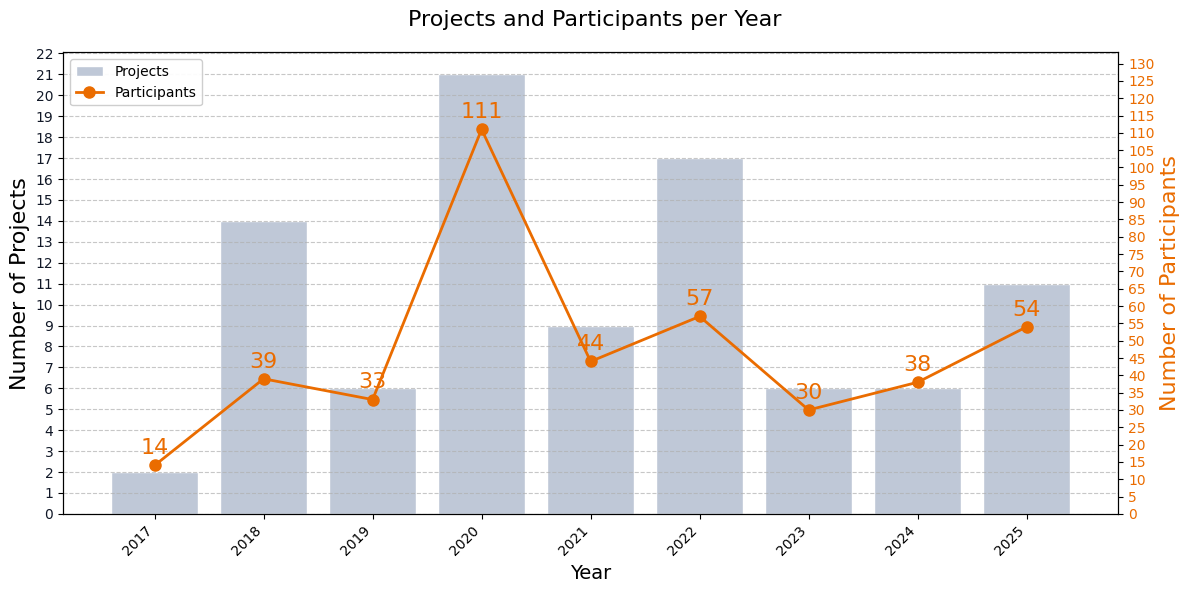

In [ ]:
years = sorted(participants_per_year.keys())
projects_counts = [projects_per_year[year] for year in years]
participants_counts = [participants_per_year[year] for year in years]

fig, ax1 = plt.subplots(figsize=(12, 6))

bars = ax1.bar(years, projects_counts, color=C_NS, hatch=CATEGORY_HATCHES[0],
               label="Projects", edgecolor="white")

ax1.set_xlabel("Year", fontsize=14)
ax1.set_ylabel("Number of Projects", fontsize=16)
ax1.tick_params(axis="y", labelcolor=C_TEXT)
ax1.set_xticks(years)
ax1.set_xticklabels(years, rotation=45, ha="right")
ax1.grid(axis="y", linestyle="--", alpha=0.7)
ax1.yaxis.set_major_locator(plt.MultipleLocator(1))

ax2 = ax1.twinx()
line, = ax2.plot(years, participants_counts, color=C_ORANGE, marker="o",
                 linewidth=2, markersize=8, label="Participants", zorder=5)
ax2.set_ylabel("Number of Participants", fontsize=16, color=C_ORANGE)
ax2.tick_params(axis="y", labelcolor=C_ORANGE)
ax2.set_ylim(0, max(participants_counts) * 1.2)
ax2.yaxis.set_major_locator(plt.MultipleLocator(5))
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v)}"))

for x, y in zip(years, participants_counts):
    ax2.annotate(f"{int(y)}", xy=(x, y), xytext=(0, 8),
                 textcoords="offset points", ha="center", fontsize=16, color=C_ORANGE)

handles = [bars, line]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc="upper left", framealpha=0.95)

fig.suptitle("Projects and Participants per Year", fontsize=16)
plt.tight_layout()
plt.show()

fig.savefig("overleaf/participants_and_projects_per_year.pdf", format="pdf")
